# Draft model
Predicts peak NBA EPM (best of the first 6 seasons, -4 if he never played) from a prospect's last
pre-draft season. Linear term on the mock pick + XGBoost on what the mock misses.

Trains on 2010-2020 mock-board players plus translated internationals. Time-ordered CV, so OOF
covers 2014-2020. 2021+ is scored but not trained on.

Data: Barttorvik, NBA Draft Room mocks, RealGM, NBA API draft history, Dunks & Threes EPM, combine.
Run top to bottom; every scrape is cached.

## 1. College stats (Barttorvik)

In [1]:
import pandas as pd
import numpy as np
import requests, io, time, os

CURRENT_SEASON = 2026   # newest class (seasons are named by end year: 2026 = 2025-26)
SHOW_ALL = False        # True prints every row of the long tables

headers = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
}

column_names = [
    'player_name', 'team', 'conf', 'GP', 'Min_per', 'ORtg', 'usg', 'eFG', 'TS_per', 'ORB_per',
    'DRB_per', 'AST_per', 'TO_per', 'FTM', 'FTA', 'FT_per', 'twoPM', 'twoPA', 'twoP_per', 'TPM',
    'TPA', 'TP_per', 'blk_per', 'stl_per', 'ftr', 'yr', 'ht', 'num', 'porpag', 'adjoe',
    'pfr', 'year', 'pid', 'type', 'Rec Rank', 'ast/tov', 'rimmade', 'rimmade+rimmiss', 'midmade', 'midmade+midmiss',
    'rimmade/(rimmade+rimmiss)', 'midmade/(midmade+midmiss)', 'dunksmade', 'dunksmiss+dunksmade', 'dunksmade/(dunksmade+dunksmiss)', 'pick', 'drtg', 'adrtg',
    'dporpag', 'stops', 'bpm', 'obpm', 'dbpm', 'gbpm', 'mp', 'ogbpm', 'dgbpm', 'oreb', 'dreb', 'treb',
    'ast', 'stl', 'blk', 'pts', 'role', '3p/100?', 'birthdate'
]

# each season is cached in barttorvik_cache/; delete a file (or set this True) to pull it again
REFRESH_BARTTORVIK = False
os.makedirs('barttorvik_cache', exist_ok=True)

all_data = []
for year in range(2010, CURRENT_SEASON + 1):
    cache = f'barttorvik_cache/{year}.csv'
    if os.path.exists(cache) and not REFRESH_BARTTORVIK:
        df = pd.read_csv(cache)
        all_data.append(df)
        print(f'{year}: {len(df)} rows (cached)')
        continue
    url = f'https://barttorvik.com/getadvstats.php?year={year}&csv=1'
    for attempt in range(6):
        try:
            print(f'Fetching {year}...')
            response = requests.get(url, headers=headers, timeout=60)
            # barttorvik keeps adding columns at the end; keep only the ones named above
            df = pd.read_csv(io.StringIO(response.text), header=None)
            df = df.iloc[:, :len(column_names)].set_axis(column_names, axis=1)
            if len(df) == 0:
                raise Exception('empty response')
            df['YEAR'] = year
            df.to_csv(cache, index=False)
            all_data.append(df)
            print(f'  -> {len(df)} rows')
            break
        except Exception as e:
            print(f'  -> failed ({e}), retrying in 5s...')
            time.sleep(5)
    else:
        raise RuntimeError(f'barttorvik {year}: 6 failed attempts')
    time.sleep(2)

combined_df = pd.concat(all_data, ignore_index=True)
print(f'Total rows: {len(combined_df)}')
print(f'Years: {sorted(combined_df["YEAR"].unique())}')

2010: 4698 rows (cached)
2011: 4548 rows (cached)
2012: 4586 rows (cached)
2013: 4608 rows (cached)
2014: 4722 rows (cached)
2015: 4723 rows (cached)
2016: 4696 rows (cached)
2017: 4742 rows (cached)
2018: 4703 rows (cached)
2019: 4739 rows (cached)
2020: 4733 rows (cached)
2021: 4970 rows (cached)
2022: 5011 rows (cached)
2023: 5043 rows (cached)
2024: 5002 rows (cached)
2025: 5060 rows (cached)
2026: 4978 rows (cached)
Total rows: 81562
Years: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


## 2. Mock drafts -> `projected_pick`
Off-board players get 99, never their real pick.

In [2]:
import requests, re, time
from bs4 import BeautifulSoup


HEADERS = {'User-Agent': 'Mozilla/5.0'}
BUBBLE_PICK = 61   # "on the bubble" / unslotted

def mock_urls(year, rnd=1):
  # boards live under /p/ or at the site root depending on the year; try the usual one first
  slug = 'nba-mock-draft' if rnd == 1 else '2nd-round'
  root, old = f'https://nbadraftroom.com/{year}-{slug}/', f'https://nbadraftroom.com/p/{year}-{slug}/'
  return [root, old] if year >= 2025 else [old, root]

# lowercase surname particles allowed mid-name (Sergio de Larrea, Tristan da Silva)
_PARTICLES = {'de', 'da', 'del', 'della', 'di', 'do', 'dos', 'das', 'du', 'van', 'von', 'der', 'den', 'la', 'le', 'el', 'ter'}

def looks_like_name(s):
  # 2+ capitalized words (particles excepted), letters and . ' - only
  parts = s.split(' ')
  if len(parts) < 2:
      return False
  for k, p in enumerate(parts):
      if not p:
          return False
      if not p[0].isupper() and not (0 < k < len(parts) - 1 and p in _PARTICLES):
          return False
      if not all(c.isalpha() or c in ".'-" for c in p):
          return False
  return True

def _one_word(s):
  # one capitalized word (some boards split first and last name over two lines)
  return bool(s) and ' ' not in s and s[0].isupper() and all(c.isalpha() or c in ".'-" for c in s)

def _is_pos(l):
  return bool(re.match(r'^(?:PG|SG|SF|PF|C|G|F)\b', l))

def _school(lines_slice):
  # first following line that starts with a dash, e.g. "– Duke – HT: 6-9 –" -> "Duke".
  # Players with no college have only metadata there ("– HT: 6-10 –"), which gives ''.
  _META = re.compile(r'^(?:HT|WT|Age|Pos|Class|Yr|DOB)\s*[:.]', re.I)
  for x in lines_slice:
      if x[:1] in ('–', '—', '-'):
          for p in re.split(r'[–—]', x):
              p = re.sub(r'\(.*?\)', '', p).strip()
              if p and not _META.match(p):
                  return p
          return ''
  return ''

MOCK_CACHE = 'mock_cache'      # one CSV per year/round; delete a file to re-scrape it
REFRESH_MOCKS = False

def scrape_mock(year, rnd=1):
  import os
  _cache = f'{MOCK_CACHE}/{year}_{rnd}.csv'
  if os.path.exists(_cache) and not REFRESH_MOCKS:
      _c = pd.read_csv(_cache, keep_default_na=False)   # blank school stays ''
      if len(_c): return _c                              # empty cache = failed scrape, retry
  out = _scrape_mock(year, rnd)
  os.makedirs(MOCK_CACHE, exist_ok=True)
  out.to_csv(_cache, index=False)
  return out

def _scrape_mock(year, rnd=1):
  out = None
  for url in mock_urls(year, rnd):
      r = requests.get(url, headers=HEADERS, timeout=30)
      if r.status_code != 200:
          continue
      out = _parse_mock(r.text, year, rnd)
      if (out['pick'] <= 60).any():
          return out
  if out is None:
      raise RuntimeError(f'no mock page found for {year} round {rnd}')
  return out

def _parse_mock(html, year, rnd):
  lo, hi = (1, 30) if rnd == 1 else (31, 60)
  _txt = BeautifulSoup(html, 'html.parser').get_text('\n').replace('’', "'").replace('‘', "'")
  # collapse whitespace and drop quoted nicknames (Nah'Shon "Bones" Hyland); line count unchanged
  lines = [re.sub(r'\s+', ' ', re.sub(r'[“"][^”"]*[”"]', ' ', l)).strip() for l in _txt.split('\n')]

  picks, backup = [], []
  last_hi = -1                                 # line of the round's last pick
  for i, l in enumerate(lines):
      if re.fullmatch(r'\d{1,2}', l) and lo <= int(l) <= hi:
          if int(l) == hi:
              last_hi = i
          # the name is the first name-like line after the pick number
          hit = None
          for j in range(i + 2, min(i + 6, len(lines))):
              if re.fullmatch(r'\d{1,2}', lines[j]):
                  break
              if looks_like_name(lines[j]):
                  hit = (lines[j], j + 1); break
          if hit is not None:
              picks.append((int(l), hit[0], _school(lines[hit[1]:hit[1] + 4])))
          else:
              # fallback: look further (skipping blank and team lines), or a name split over two lines
              nb_ = []
              for j in range(i + 2, len(lines)):
                  if re.fullmatch(r'\d{1,2}', lines[j]): break
                  if lines[j]: nb_.append(j)
                  if len(nb_) == 6: break
              hit = next(((lines[j], j + 1) for j in nb_ if looks_like_name(lines[j])), None)
              if hit is None:
                  for a, b in zip(nb_, nb_[1:]):
                      if _one_word(lines[a]) and _one_word(lines[b]):
                          hit = (lines[a] + ' ' + lines[b], b + 1); break
              if hit is not None:
                  backup.append((int(l), hit[0], _school(lines[hit[1]:hit[1] + 4])))
  # fallbacks only fill pick numbers the main rule missed
  _have = {p_[0] for p_ in picks}
  picks += [b_ for b_ in backup if b_[0] not in _have]
  df = pd.DataFrame(picks, columns=['pick', 'player_name', 'school']).drop_duplicates('pick').sort_values('pick')

  # bubble players (2nd round page, after pick 60) all get BUBBLE_PICK. A bubble player is a name
  # followed by a position line, which is what separates them from player comps.
  bubble = []
  if rnd == 2 and last_hi >= 0:
      slotted = set(df['player_name'])
      for i in range(last_hi + 1, len(lines)):
          l = lines[i]
          if looks_like_name(l) and l not in slotted and any(_is_pos(x) for x in lines[i + 1:i + 3]):
              bubble.append((l, _school(lines[i + 1:i + 5])))
  bubble = list(dict.fromkeys(bubble))
  bdf = pd.DataFrame(bubble, columns=['player_name', 'school'])
  bdf['pick'] = BUBBLE_PICK

  out = pd.concat([df, bdf], ignore_index=True)
  out['year'] = year
  out['round'] = rnd
  return out

In [3]:
# projected_pick = the player's slot on THAT year's pre-draft mock board (bubble 61, off-board 99).
# Never the real pick: it carries draft-night information a prospect being scored doesn't have.
#
# Barttorvik -> board matching, in priority order:
#   1) last name: exact, or a near-miss (Sharp/Sharpe) that also needs the school to match
#   2) school
#   3) first name (exact, nickname, prefix, or a letter or two off), then the earlier pick
import numpy as np, re
from collections import defaultdict

UNDRAFTED = 99

# nicknames that aren't simple prefixes
NICK = {'mike': 'michael', 'chris': 'christopher', 'matt': 'matthew', 'nick': 'nicholas',
        'tony': 'anthony', 'will': 'william', 'rob': 'robert', 'bob': 'robert', 'joe': 'joseph',
        'dan': 'daniel', 'danny': 'daniel', 'dave': 'david', 'josh': 'joshua', 'zach': 'zachary',
        'ben': 'benjamin', 'sam': 'samuel', 'alex': 'alexander', 'nate': 'nathan', 'ed': 'edward',
        'tim': 'timothy', 'jon': 'jonathan', 'pat': 'patrick', 'greg': 'gregory', 'andy': 'andrew',
        'drew': 'andrew', 'cam': 'cameron', 'vince': 'vincent', 'gabe': 'gabriel',
        'moe': 'maurice'}
def _canon(f): return NICK.get(f, f)

def norm_name(s):
    s = str(s).lower()
    s = re.sub(r'\b(jr|sr|ii|iii|iv)\b\.?', '', s)
    s = s.replace('.', '').replace(',', '').replace('-', ' ').replace("'", '')
    return re.sub(r'\s+', ' ', s).strip()
def _skey(s):         # school, letters only
    return re.sub(r'[^a-z]', '', str(s).lower())
def _first_last(n):
    p = norm_name(n).split()
    return (p[0], p[-1]) if len(p) >= 2 else ('', norm_name(n))

def _lev(a, b):       # edit distance (9 if the lengths differ by more than 2)
    if a == b: return 0
    m, n = len(a), len(b)
    if abs(m - n) > 2: return 9
    prev = list(range(n + 1))
    for i in range(1, m + 1):
        cur = [i] + [0] * n
        for j in range(1, n + 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (a[i - 1] != b[j - 1]))
        prev = cur
    return prev[n]

def _name_score(bf, mf):
    if bf == mf:                    return 100
    if _canon(bf) == _canon(mf):    return 70    # Nate/Nathan
    if len(mf) >= 2 and len(bf) >= 2 and (mf.startswith(bf) or bf.startswith(mf)):
                                    return 60    # Cam/Cameron
    d = _lev(bf, mf)
    if d == 1:                      return 55    # Henri/Henry
    if d == 2 and min(len(bf), len(mf)) >= 5:
                                    return 45
    return 0

def _last_score(bl, ml):
    if bl == ml:                    return 100
    if len(bl) == len(ml) >= 5:     # two adjacent letters swapped (Hield/Heild)
        _d = [k for k in range(len(bl)) if bl[k] != ml[k]]
        if len(_d) == 2 and _d[1] == _d[0] + 1 and bl[_d[0]] == ml[_d[1]] and bl[_d[1]] == ml[_d[0]]:
                                    return 60
    if len(bl) >= 4 and len(ml) >= 4 and abs(len(bl) - len(ml)) == 1 and \
       (ml.startswith(bl) or bl.startswith(ml)):
                                    return 80    # Sharp/Sharpe
    if _lev(bl, ml) == 1 and min(len(bl), len(ml)) >= 6:
                                    return 60
    return 0

# keeps the priority strict: any exact last name outscores any fuzzy one
LAST_WEIGHT  = 10000
SCHOOL_BONUS = 1000

# Barttorvik names the board spells differently: (class, Barttorvik name) -> board name
MOCK_NAME_ALIASES = {
    (2011, 'etwaun moore'):   'e twaun moore',
    (2012, 'jeffery taylor'): 'jeffrey taylor',
    (2017, 'edrice adebayo'): 'bam adebayo',
    (2019, 'pj washington'):  'paul washington',
    (2022, 'aj griffin'):     'adrian griffin',
}

def _match_pick(name, team, by_last, last_names, year=None):
    name = MOCK_NAME_ALIASES.get((year, norm_name(name)), name)
    bf, bl = _first_last(name); bs = _skey(team)
    best_pick, best_eid, best_score = None, None, 0
    for ml in last_names:
        if abs(len(ml) - len(bl)) > 1:
            continue
        ls = _last_score(bl, ml)
        if ls == 0:
            continue
        for mf, ms, pk, eid in by_last[ml]:
            ns = _name_score(bf, mf)
            if ns == 0:
                continue
            school_match = bool(bs and ms and bs == ms)
            no_school = not ms                     # 2010-2016 boards list no schools
            if ls == 100:
                # fuzzy first name needs the school (or one letter off on a school-less board)
                if ns < 60 and not school_match and not (no_school and ns >= 55):
                    continue
            elif not school_match and not (no_school and ns == 100):
                continue                           # fuzzy last name needs the school
            score = LAST_WEIGHT * ls + (SCHOOL_BONUS if school_match else 0) + ns
            if score > best_score or (score == best_score and best_pick is not None and pk < best_pick):
                best_pick, best_eid, best_score = pk, eid, score
    return best_pick, best_eid, best_score

def mock_board(year):
    return pd.concat([scrape_mock(year, 1), scrape_mock(year, 2)], ignore_index=True)

def match_board(year, mock):
    """(all claims, winners). Each board entry goes to its best-scoring Barttorvik row; ties go to
    the higher BPM (2011: Tristan Thompson of Texas, not the one at North Texas)."""
    by_last = defaultdict(list)
    for eid, r in enumerate(mock.itertuples(index=False)):
        f, l = _first_last(r.player_name)
        by_last[l].append((f, _skey(r.school), int(r.pick), eid))
    rows = combined_df[combined_df['YEAR'] == year]
    res = rows.apply(lambda r: _match_pick(r['player_name'], r['team'], by_last, list(by_last), year),
                     axis=1, result_type='expand')
    res.columns = ['pk', 'eid', 'score']
    hit = res[res['eid'].notna()]
    win = (hit.assign(_bpm=pd.to_numeric(combined_df.loc[hit.index, 'bpm'], errors='coerce'))
              .sort_values(['score', '_bpm'], ascending=False, kind='stable')
              .drop_duplicates('eid', keep='first'))
    return hit, win

proj = pd.Series(np.nan, index=combined_df.index)
for _yr in sorted(combined_df['YEAR'].unique()):
    try:
        _mock = mock_board(_yr)
    except Exception as _e:
        print(f'{_yr}: mock scrape failed ({_e}) -> all off-board'); continue
    _hit, _win = match_board(_yr, _mock)
    proj.loc[_win.index] = _win['pk'].values
    print(f"{_yr}: {int((combined_df['YEAR'] == _yr).sum()):>5} rows, {len(_win):>3} matched "
          f"({len(_hit) - len(_win)} dup claims dropped)")

combined_df['projected_pick'] = proj.fillna(UNDRAFTED).astype(int)

# drafted players not found on their year's board (worth a look for name mismatches)
_pk = pd.to_numeric(combined_df['pick'], errors='coerce')
_final = combined_df['YEAR'] == combined_df.groupby('pid')['YEAR'].transform('max')
_unplaced = combined_df[_final & _pk.between(1, 60) & proj.isna()]
print(f"\ndrafted, but not on their year's mock board (off-board, not trained on): {len(_unplaced)}")
print(_unplaced.sort_values('YEAR')[['YEAR', 'player_name', 'team', 'pick']].to_string(index=False))

print(f'\n{CURRENT_SEASON} class by projected_pick:')
print(combined_df.loc[combined_df['YEAR'] == CURRENT_SEASON, ['player_name', 'team', 'projected_pick']]
      .sort_values('projected_pick').head(60 if SHOW_ALL else 15).to_string(index=False))

2010:  4698 rows,  70 matched (3 dup claims dropped)
2011:  4548 rows,  72 matched (6 dup claims dropped)
2012:  4586 rows,  74 matched (5 dup claims dropped)
2013:  4608 rows,  67 matched (0 dup claims dropped)
2014:  4722 rows,  60 matched (5 dup claims dropped)
2015:  4723 rows,  59 matched (1 dup claims dropped)
2016:  4696 rows,  59 matched (2 dup claims dropped)
2017:  4742 rows,  67 matched (4 dup claims dropped)
2018:  4703 rows,  64 matched (1 dup claims dropped)
2019:  4739 rows,  89 matched (1 dup claims dropped)
2020:  4733 rows,  90 matched (2 dup claims dropped)
2021:  4970 rows,  95 matched (6 dup claims dropped)
2022:  5011 rows,  90 matched (3 dup claims dropped)
2023:  5043 rows,  81 matched (1 dup claims dropped)
2024:  5002 rows,  72 matched (3 dup claims dropped)
2025:  5060 rows,  90 matched (3 dup claims dropped)
2026:  4978 rows,  91 matched (0 dup claims dropped)

drafted, but not on their year's mock board (off-board, not trained on): 43
 YEAR           player

## 3. Internationals
RealGM stats, translated to NCAA level by league.

In [4]:
# Internationals = mock-board names no college player claimed. Scraped from RealGM (stats + bio),
# resumable: names already in intl_scraped.csv are skipped.
import cloudscraper, time, unicodedata, re, os
from difflib import SequenceMatcher
from bs4 import BeautifulSoup
from io import StringIO
from urllib.parse import quote
import pandas as pd

_cs = cloudscraper.create_scraper(browser={'browser': 'chrome', 'platform': 'darwin', 'mobile': False})

def _map_league(name):
    """RealGM league label -> translation-table key, or None (cups, juniors, lower divisions)."""
    n = str(name).lower().strip()
    if 'euroleague' in n: return 'Euroleague'          # before the 'cup' check
    if 'eurocup' in n:    return 'Eurocup'
    if any(w in n for w in ['cup', 'espoirs', 'angt', 'kaunas', 'all leagues', 'supercup', 'blitz',
                            'a2', 'a-1', 'feb', 'pro b', 'nm1', 'skl', 'bnxt', 'next gen',
                            'u18', 'u16', 'u21', 'junior', 'friendly']):
        return None
    if 'bsl' in n:
        return 'Israeli-BSL' if ('i-bsl' in n or 'israel' in n) else 'Turkish-BSL'
    for kw, key in [('jeep','French-Jeep-Elite'), ('lnb pro a','French-Jeep-Elite'), ('betclic','French-Jeep-Elite'),
                    ('aba','Adriatic-League-Liga-ABA'), ('adriatic','Adriatic-League-Liga-ABA'),
                    ('acb','Spanish-ACB'), ('endesa','Spanish-ACB'),
                    ('bbl','German-BBL'),
                    ('lega','Italian-Lega-Basket-Serie-A'), ('lba','Italian-Lega-Basket-Serie-A'),
                    ('nbl','Australian-NBL'),
                    ('heba','Greek-HEBA-A1'),
                    ('vtb','VTB-United-League'),
                    ('lkl','Lithuanian-LKL'),
                    ('ignite','G-League (Ignite only)'), ('g-league','G-League (Ignite only)')]:
        if kw in n:
            return key
    return None

def _get(url, tries=4, sleep=3):
    """GET with retries; RealGM 403s come and go, so each retry starts a fresh session."""
    global _cs
    for a in range(tries):
        try:
            r = _cs.get(url, timeout=40)
            if r.status_code == 200: return r
        except Exception: pass
        _cs = cloudscraper.create_scraper(browser={'browser': 'chrome', 'platform': 'darwin', 'mobile': False})
        time.sleep(sleep)
    return None

class Blocked(Exception):
    pass

def _norm_name(s):
    s = unicodedata.normalize('NFKD', str(s)); s = ''.join(c for c in s if not unicodedata.combining(c))
    return re.sub(r'[^a-z ]', '', s.lower()).strip()

def _clean_name(s):
    return re.sub(r'-(?=[a-z])', '', str(s)).strip()   # "Wemban-yama" -> "Wembanyama", keeps "Gilgeous-Alexander"

def find_intl_projected():
    intl = []
    for yr in sorted(combined_df['YEAR'].unique()):
        try:
            mock = mock_board(yr)
        except Exception as e:
            print(f"{yr}: mock scrape failed ({e})"); continue
        claimed = set(match_board(yr, mock)[1]['eid'].astype(int))
        for eid, r in enumerate(mock.itertuples(index=False)):
            if eid not in claimed:
                intl.append({'year': yr, 'player_name': _clean_name(r.player_name), 'pick': int(r.pick),
                             'school': getattr(r, 'school', '')})
        print(f"{yr}: {len(mock)} mock, {len(claimed)} claimed by college, {len(mock)-len(claimed)} international")
    return pd.DataFrame(intl)

def _match_score(qn, cn):
    qp, cp = qn.split(), cn.split()
    if not qp or not cp: return 0.0
    first = SequenceMatcher(None, qp[0], cp[0]).ratio()
    last  = SequenceMatcher(None, qp[-1], cp[-1]).ratio()
    return 0.7 * first + 0.3 * last     # first name weighted up: the search already matched the surname

def realgm_url(name, min_score=0.72):
    """(url, matched_name, score); url is None below min_score."""
    _asc = lambda s: unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode()  # Şengün -> Sengun
    full, last = _asc(name), _asc(name.split()[-1])
    # full name first (a surname search for "Green" buries Jalen Green), surname as the fallback
    cands = []
    for q in ([full, last] if full != last else [last]):
        r = _get("https://basketball.realgm.com/search?q=" + quote(q))
        if r is None: continue
        if '/Summary/' in getattr(r, 'url', ''):        # single hit redirects straight to the player
            return r.url, name, 1.0
        soup = BeautifulSoup(r.text, 'html.parser')
        cands = [(a.get_text(strip=True), a['href']) for a in soup.find_all('a', href=True)
                 if '/player/' in a['href'] and '/Summary/' in a['href']]
        if cands: break
    if not cands: return None, None, 0.0
    nn = _norm_name(name)
    scored = sorted(((_match_score(nn, _norm_name(t)), t, h) for t, h in cands), reverse=True)
    sc, mname, href = scored[0]
    url = ("https://basketball.realgm.com" + href) if sc >= min_score else None
    return url, mname, round(sc, 2)

def _parse_bio(soup):
    t = soup.get_text(' ', strip=True); bio = {}
    m = re.search(r'Height:\s*(\d+)-(\d+)', t)
    if m: bio['height_in'] = int(m.group(1)) * 12 + int(m.group(2))
    m = re.search(r'Weight:\s*(\d+)\s*lbs', t)
    if m: bio['weight_lbs'] = int(m.group(1))
    m = re.search(r'Born:\s*([A-Z][a-z]{2}\.?\s*\d{1,2},\s*\d{4})', t)
    if m: bio['born'] = m.group(1)
    return bio

_TOTALS = ['FGM','FGA','3PM','3PA','FTM','FTA','3P%','FT%','AST','TOV','PF','MIN','MPG']

def _page(url):
    r = _get(url)
    if r is None: raise Blocked(url)          # retryable, unlike a page with no stats section
    return BeautifulSoup(r.text, 'html.parser')

def _section(soup, h, keys):
    """Advanced table (the one with TS%) under heading h, with totals merged in, plus bio."""
    adv = tot = None
    for el in h.find_all_next():
        if el.name in ('h2', 'h3'): break
        if el.name == 'table':
            df = pd.read_html(StringIO(str(el)))[0]; cols = [str(c) for c in df.columns]
            if 'TS%' in cols: adv = df
            elif 'FGA' in cols and tot is None: tot = df
    if adv is None: return None
    if tot is not None:
        keys = [k for k in keys if k in adv.columns and k in tot.columns]
        add = [c for c in _TOTALS if c in tot.columns and c not in adv.columns]
        if keys: adv = adv.merge(tot[keys + add], on=keys, how='left')
    for k, v in _parse_bio(soup).items():
        adv[k] = v
    return adv

def scrape_realgm_intl(url):
    soup = _page(url)
    # exact heading, so a current-season game log above it isn't picked up
    h = next((t for t in soup.find_all(['h2', 'h3'])
              if t.get_text(strip=True) == 'International Season Stats'), None)
    return None if h is None else _section(soup, h, ['Season', 'Team', 'League'])

def scrape_realgm_gleague(url):
    soup = _page(url)
    def _is_hdr(t):
        x = t.get_text(strip=True)
        return (bool(re.search(r'(g\s*league|d-?league)', x, re.I)) and 'Season Stats' in x
                and not re.match(r'^\d{4}', x))       # skip "2025-26 ..." game logs
    h = next((t for t in soup.find_all(['h2', 'h3']) if _is_hdr(t)), None)
    adv = None if h is None else _section(soup, h, ['Season', 'Team'])
    if adv is not None:
        adv['League'] = 'G-League'
    return adv

def scrape_intl_players(names, out_csv='intl_scraped.csv', sleep=4.0, url_overrides=None,
                        gleague_only=None):
    url_overrides = url_overrides or {}                   # {name: url} manual fixes
    gleague_only  = set(gleague_only or ())               # read only the G League section for these
    try:
        done = set(pd.read_csv(out_csv)['player_name'].unique()) if os.path.exists(out_csv) else set()
    except Exception:
        done = set()
    if done: print(f"resuming, {len(done)} already scraped")
    failed = []
    for i, nm in enumerate(names):
        if nm in done: continue
        try:
            if nm in url_overrides:
                url, mname, sc = url_overrides[nm], nm, 1.0
            else:
                url, mname, sc = realgm_url(nm)
            if not url:
                failed.append((nm, f'no confident match (best={mname!r} {sc})'))
                print(f"[{i+1}/{len(names)}] {nm}: NO confident match (best={mname!r} score={sc})")
                time.sleep(sleep); continue
            try:
                if nm in gleague_only:
                    # their international section is junk (Ron Holland: one Intercontinental Cup game)
                    adv = scrape_realgm_gleague(url)
                else:
                    adv = scrape_realgm_intl(url)
                    if adv is None or adv.empty:
                        adv = scrape_realgm_gleague(url)
            except Blocked:
                failed.append((nm, 'BLOCKED (re-run to retry)')); print(f"[{i+1}/{len(names)}] {nm}: BLOCKED, re-run later")
                time.sleep(sleep * 2); continue
            if adv is None or adv.empty:
                failed.append((nm, 'no intl AND no G League section'))
                print(f"[{i+1}/{len(names)}] {nm}: no intl and no G League section")
                time.sleep(sleep); continue
            new = adv.copy(); new.insert(0, 'player_name', nm)
            new['matched_name'] = mname; new['match_score'] = sc; new['url'] = url
            if os.path.exists(out_csv):
                try: full = pd.concat([pd.read_csv(out_csv), new], ignore_index=True)
                except Exception: full = new
            else:
                full = new
            full.to_csv(out_csv, index=False)
            print(f"[{i+1}/{len(names)}] {nm} -> {mname} ({sc}): OK (+{len(new)} rows, {len(full)} total)")
        except Exception as e:
            failed.append((nm, str(e)[:50])); print(f"[{i+1}/{len(names)}] {nm}: ERR {e}")
        time.sleep(sleep)
    print(f"\ndone. failures ({len(failed)}): {failed}")
    return failed

# full re-scrape: scrape_intl_players(find_intl_projected()['player_name'].unique())

## Add an international by hand
Paste his RealGM Summary link, draft year and mock pick.

In [5]:
# name: how he's shown (and the join key)   url: RealGM Summary page   year: draft year
# pick: projected pick 1-60, or 61 for the bubble   school: optional (club / country)
import os, pandas as pd

RESCRAPE = False      # True = drop his scraped rows and pull the page again

MANUAL_INTL = [
    {'name': 'Sergio de Larrea', 'url': 'https://basketball.realgm.com/player/Sergio-De-Larrea/Summary/175825', 'year': 2026, 'pick': 30, 'school': 'Valencia'},
]

_todo = [m for m in MANUAL_INTL if str(m.get('url', '')).strip()]
for m in MANUAL_INTL:
    if m not in _todo: print(f"skipping {m['name']}: no url yet")

if _todo:
    _il = pd.read_csv('intl_list.csv') if os.path.exists('intl_list.csv') else pd.DataFrame(columns=['year', 'player_name', 'pick', 'school'])
    _names = {m['name'] for m in _todo}
    _il = _il[~_il['player_name'].isin(_names)]
    _il = pd.concat([_il, pd.DataFrame([{'year': int(m['year']), 'player_name': m['name'], 'pick': int(m['pick']),
                                         'school': m.get('school', '')} for m in _todo])], ignore_index=True)
    _il.sort_values(['year', 'pick'], kind='stable').to_csv('intl_list.csv', index=False)

    if RESCRAPE and os.path.exists('intl_scraped.csv'):
        _s = pd.read_csv('intl_scraped.csv')
        _s[~_s['player_name'].isin(_names)].to_csv('intl_scraped.csv', index=False)
    _fails = scrape_intl_players([m['name'] for m in _todo],
                                 url_overrides={m['name']: m['url'].strip() for m in _todo}, sleep=2.0)

    _s = pd.read_csv('intl_scraped.csv')
    for m in _todo:
        _n = int((_s['player_name'] == m['name']).sum())
        print(f"{m['name']:<24} {m['year']}  pick {m['pick']:>2}   scraped rows: {_n}"
              + ('' if _n else '   <- nothing scraped (check the link, or RealGM is blocking: re-run later)'))

resuming -- 235 already scraped

done. failures (0): []
Sergio de Larrea         2026  pick 30   scraped rows: 21


In [6]:
# Each international's pre-draft season: the latest season ending by his draft year. primary_league
# (the league he played the most games in) decides the translation.
import re
def _season_end_year(s):
    m = re.match(r'(\d{4})-\d{2}', str(s)); return int(m.group(1)) + 1 if m else None   # "2022-23" -> 2023

def intl_predraft_rows(scraped, draft_years):
    """One row per player: the pre-draft season total + primary_league + bio."""
    _all = lambda col: col.astype(str).str.contains('All League', case=False, na=False)
    out = []
    for nm, g in scraped.groupby('player_name'):
        dy = draft_years.get(nm)
        if dy is None: continue
        g = g.copy(); g['_end'] = g['Season'].map(_season_end_year)
        elig = g[g['_end'].notna() & (g['_end'] <= dy)]
        if elig.empty: continue
        season = g.loc[elig['_end'].idxmax(), 'Season']
        sg = g[g['Season'] == season]
        agg = sg[_all(sg['League'])]
        if agg.empty:
            # RealGM only adds an "All Leagues" row for multi-league seasons; otherwise the one row is the total
            _per = sg[~_all(sg['League'])].copy()
            if _per.empty: continue
            _per['_gp'] = pd.to_numeric(_per['GP'], errors='coerce')
            agg = _per.sort_values('_gp', ascending=False).head(1)
        row = agg.iloc[0].to_dict()
        per = sg[~_all(sg['League'])].copy()
        per['_gp'] = pd.to_numeric(per['GP'], errors='coerce')
        per['_ok'] = per['League'].map(lambda l: _map_league(l) is not None)
        per = per[per['_gp'].notna()]
        # most games wins, so a cameo can't decide it (Pokusevski: 11 HEBA A2 games, 1 Euroleague).
        # A translatable league only breaks an exact tie.
        if per.empty:
            row['primary_league'] = None
        else:
            _tied = per[per['_gp'] == per['_gp'].max()]
            _pick = _tied[_tied['_ok']] if _tied['_ok'].any() else _tied
            row['primary_league'] = _pick.iloc[0]['League']
        row['player_name'] = nm; row['season'] = season; row['draft_year'] = dy
        out.append(row)
    return pd.DataFrame(out)

In [7]:
# International rows for the model: RealGM columns -> model features, translated to NCAA level by
# the primary league (stat * exp(league factor - NCAA factor)).
import numpy as np, pandas as pd

# RealGM column -> (model feature, multiply by 100?)
INTL_MAP = {
    'USG%': ('usg', False), 'ORB%': ('ORB_per', False), 'DRB%': ('DRB_per', False),
    'AST%': ('AST_per', False), 'TOV%': ('TO_per', False), 'STL%': ('stl_per', False),
    'BLK%': ('blk_per', False), 'ORtg': ('ORtg', False),
    'TS%':  ('TS_per', True),
    'FT%':  ('FT_per', False), '3P%': ('TP_per', False),
}

# flat EPM discount for internationals whose league has no translation factors
UNMAPPED_PENALTY = 3.0

def build_intl_model_rows(pre, intl, factors_csv="NBA Draft probabilities - league translations.csv"):
    lt = pd.read_csv(factors_csv).set_index('league').rename(columns={
        'usg':'usg','TS%':'TS_per','ORB%':'ORB_per','DRB%':'DRB_per','AST%':'AST_per',
        'TO%':'TO_per','ast/tov':'ast/tov','BLK%':'blk_per','STL%':'stl_per','ftr':'ftr',
        'FT%':'FT_per','3P%':'TP_per','ORtg':'ORtg'})
    T = lt.to_dict('index'); ncaa = T.get('NCAA', {})
    pick_of = dict(zip(intl['player_name'], pd.to_numeric(intl['pick'], errors='coerce')))
    num = lambda r, c: pd.to_numeric(r.get(c), errors='coerce')
    ratio = lambda a, b: a / b if (pd.notna(a) and pd.notna(b) and b) else np.nan
    rows = []
    for _, r in pre.iterrows():
        f = {}
        for rg, (mf, x100) in INTL_MAP.items():
            v = num(r, rg)
            f[mf] = (v * 100 if x100 else v) if pd.notna(v) else np.nan
        _fga = num(r, 'FGA')
        f['ast/tov'] = ratio(num(r, 'AST'), num(r, 'TOV'))
        f['ftr']     = ratio(100 * num(r, 'FTA'), _fga)          # 0-100, like barttorvik
        f['3par']    = ratio(num(r, '3PA'), _fga)
        f['twoP_per'] = ratio(num(r, 'FGM') - num(r, '3PM'), _fga - num(r, '3PA'))

        lg  = _map_league(r.get('primary_league'))
        src = T.get(lg, {}) if lg else {}
        _is_g = (lg == 'G-League (Ignite only)')
        for mf in list(f):
            if _is_g and mf == 'ftr': continue            # G League ftr factor is way off (1.034); skip it
            if mf in src and mf in ncaa and pd.notna(f[mf]):
                f[mf] = f[mf] * np.exp(src[mf] - ncaa[mf])

        # The table has no 2P% factor, so back it out of the translated TS%, 3P%, FT%, 3par and ftr:
        #     TS% = [2*p2*(1-3par) + 3*3P%*3par + FT%*ftr] / [2*(1 + 0.44*ftr)]
        # (Luka 2017-18: reproduces his TS% to 0.001; ACB takes his 2P% from .580 to .547.)
        # Not for the G League, where the bad ftr factor breaks it.
        if not _is_g:
            _sc  = lambda v: (v / 100.0 if pd.notna(v) and v > 2 else v)   # accept 0-100 or 0-1
            _ts, _p3 = _sc(f.get('TS_per')), f.get('TP_per')
            _pf, _a, _rt = f.get('FT_per'), f.get('3par'), _sc(f.get('ftr'))
            if all(pd.notna(x) for x in (_ts, _p3, _pf, _a, _rt)) and (1 - _a) > 0.05:
                _p2 = (2*_ts*(1 + 0.44*_rt) - 3*_p3*_a - _pf*_rt) / (2*(1 - _a))
                if 0.20 <= _p2 <= 0.85:                   # outside this, keep the raw number
                    f['twoP_per'] = _p2

        f['realgm_league'] = r.get('primary_league')
        f['translated_from'] = lg or f"UNMAPPED:{r.get('primary_league')}"
        f['ht_inches'] = num(r, 'height_in')
        f['WEIGHT']    = num(r, 'weight_lbs')
        _born = pd.to_datetime(r.get('born'), errors='coerce'); _dy = r.get('draft_year')
        if pd.notna(_born) and pd.notna(_dy):
            f['age'] = (pd.Timestamp(int(_dy), 2, 1) - _born).days / 365.25    # Feb 1, same as college
        f['projected_pick'] = pick_of.get(r['player_name'])
        f['player_name'] = r['player_name']; f['YEAR'] = _dy; f['is_intl'] = True
        rows.append(f)
    return pd.DataFrame(rows)

## 4. College feature prep

In [8]:
# age on Feb 1 of the season, from the barttorvik birthdate
combined_df['birthdate'] = pd.to_datetime(combined_df['birthdate'], errors='coerce')
_feb1 = pd.to_datetime(combined_df['YEAR'].astype(str) + '-02-01')
combined_df['age'] = (_feb1 - combined_df['birthdate']).dt.days / 365.25
print('age coverage:', combined_df['age'].notna().sum(), '/', len(combined_df))

def height_to_inches(ht_str):
    if pd.isna(ht_str) or ht_str == '' or ht_str == 'NaN':
        return None
    try:
        parts = str(ht_str).split('-')
        if len(parts) == 2:
            return int(parts[0]) * 12 + int(parts[1])
    except:
        return None

combined_df['ht_inches'] = combined_df['ht'].apply(height_to_inches)

for col in ['gbpm', 'obpm', 'dbpm', 'usg', 'eFG', 'TS_per', 'ORB_per', 'DRB_per',
            'AST_per', 'TO_per', 'blk_per', 'stl_per', 'Min_per', 'adjoe', 'porpag']:
    combined_df[col] = pd.to_numeric(combined_df[col], errors='coerce')

print(combined_df[['player_name', 'YEAR', 'ht_inches', 'Min_per']].head())

age coverage: 81547 / 81562
     player_name  YEAR  ht_inches  Min_per
0  Pooh Williams  2010       75.0     64.0
1   Nick Rodgers  2010       74.0      1.0
2     Dana Smith  2010       77.0     81.8
3      Matt Beck  2010       72.0      1.3
4    Alex Hornat  2010       77.0      0.2


## 5. NBA outcomes and the training target

In [9]:
import os
from nba_api.stats.endpoints import drafthistory

# NBA draft history, cached to nba_draft_history_raw.csv; delete it (or set this True) after a new draft
REFRESH_DRAFT = False
if os.path.exists('nba_draft_history_raw.csv') and not REFRESH_DRAFT:
    draft = pd.read_csv('nba_draft_history_raw.csv')
else:
    draft = drafthistory.DraftHistory(timeout=60).get_data_frames()[0]
    draft.to_csv('nba_draft_history_raw.csv', index=False)
draft = draft[['PERSON_ID', 'PLAYER_NAME', 'SEASON', 'ROUND_NUMBER', 'ROUND_PICK', 'OVERALL_PICK', 'ORGANIZATION']]
draft = draft.rename(columns={'PERSON_ID': 'nba_id', 'SEASON': 'draft_year'})
draft['ROUND_NUMBER'] = draft['ROUND_NUMBER'].fillna(0).astype(int)
draft['OVERALL_PICK'] = draft['OVERALL_PICK'].fillna(999).astype(int)
draft['is_first_round'] = (draft['ROUND_NUMBER'] == 1).astype(int)
draft['draft_year'] = draft['draft_year'].astype(str).str[:4].astype(int)

print(f'Draft: {draft.shape}, classes {draft["draft_year"].min()}-{draft["draft_year"].max()}')

Draft: (8434, 8), classes 1947-2026


In [10]:
# One row per college player (drafted or not) + the target: peak EPM over his first 6 NBA seasons.
import re, glob, os, numpy as np, pandas as pd

# key on pid, not name: two players with the same name would otherwise merge into one row
combined_df['_pkey'] = combined_df['pid'].astype(str)
_nopid = combined_df['pid'].isna()
combined_df.loc[_nopid, '_pkey'] = 'name:' + combined_df.loc[_nopid, 'player_name'].astype(str)
_coll = combined_df.groupby('player_name')['_pkey'].nunique()
_coll = _coll[_coll > 1]
print(f"name collisions resolved by keying on pid: {len(_coll)} names map to >1 player")
if len(_coll): print('   e.g. ' + ', '.join(_coll.index[:12]))

# stats = his last season with real minutes; draft class = his last season, period
allc = (combined_df[combined_df['Min_per'] >= 25]
        .sort_values('YEAR').groupby('_pkey').last().reset_index())
allc['name_key'] = allc['player_name'].apply(norm_name)
allc['draft_year'] = allc['_pkey'].map(combined_df.groupby('_pkey')['YEAR'].max())

# the mock pick comes from the draft year's board, even when the stats row is the season before
# (a short final season: Cedric Coward 2025, Jayden Quaintance 2026)
_dy_row = combined_df['YEAR'] == combined_df.groupby('_pkey')['YEAR'].transform('max')
allc['projected_pick'] = (allc['_pkey'].map(combined_df[_dy_row].groupby('_pkey')['projected_pick'].min())
                              .fillna(allc['projected_pick']).astype(int))

# NBA EPM (Dunks & Threes), same load as longterm_darko: for each season, the newest download.
# Old and re-downloaded files use different methods (~0.9 EPM apart), so they can't be mixed.
def last_complete_season(today=None):
    """A season (named by end year) counts as finished from July 1."""
    today = pd.Timestamp.today() if today is None else pd.Timestamp(today)
    return today.year if today.month >= 7 else today.year - 1

def _newest_per_season(pattern, through=None):
    through = last_complete_season() if through is None else through
    files = glob.glob(pattern)
    if not files:
        raise FileNotFoundError(f"no '{pattern}' files")
    df = pd.concat([pd.read_csv(f).assign(_mtime=os.path.getmtime(f), _file=f) for f in files],
                   ignore_index=True)
    df = df.dropna(subset=['season'])
    df = df[df['season'].astype(int) <= through]
    df = df[df['_mtime'] == df.groupby('season')['_mtime'].transform('max')]
    print(f"{pattern}: {df['_file'].nunique()} of {len(files)} files used, "
          f"seasons {int(df['season'].min())}-{int(df['season'].max())} (newest download per season)")
    return df.drop(columns=['_mtime', '_file'])

epm = _newest_per_season('EPM data*.csv')
epm = epm[['season','nba_id','name','epm']].dropna(subset=['nba_id'])
epm['nba_id'] = epm['nba_id'].astype(int); epm['season'] = epm['season'].astype(int)
epm['name_key'] = epm['name'].apply(norm_name)

# college player -> nba_id, two steps:
#   1) draft history: drafted in his last college year or the next, same last name, and the first
#      name or school agrees (school alone only if no teammate shares the surname). Handles Edrice ->
#      Bam Adebayo, and sons who share a father's name (Jaren Jackson Jr.).
#   2) everyone else by name, only if exactly one NBA id fits and his first EPM season is 1-6 years
#      out. Names come from every EPM file, since players get renamed (Nigel Hayes -> Hayes-Davis).
_dh = draft[['nba_id', 'PLAYER_NAME', 'draft_year', 'ORGANIZATION']].copy()
_dh['name_key'] = _dh['PLAYER_NAME'].apply(norm_name)
_dh['_first'], _dh['_last'] = zip(*_dh['PLAYER_NAME'].map(_first_last))
_dh['_school'] = _dh['ORGANIZATION'].map(_skey)
_dh_by = {k: g for k, g in _dh.groupby(['draft_year', '_last'])}
_roster_last = (combined_df.assign(_l=combined_df['player_name'].map(lambda n: _first_last(n)[1]),
                                   _s=combined_df['team'].map(_skey))
                .groupby(['YEAR', '_s', '_l'])['_pkey'].nunique().to_dict())

_claims = []
for _i, _r in allc[['name_key', 'player_name', 'team', 'draft_year']].iterrows():
    _bf, _bl = _first_last(_r['player_name']); _bs = _skey(_r['team'])
    for _dy, _late in ((int(_r['draft_year']), 0), (int(_r['draft_year']) + 1, 1)):
        for _, _c in _dh_by.get((_dy, _bl), pd.DataFrame()).iterrows():
            _school = bool(_bs) and _bs == _c['_school']
            _first = _name_score(_bf, _c['_first']) >= 60
            _exact = _r['name_key'] == _c['name_key']
            if _school and not (_first or _exact) and \
               _roster_last.get((int(_r['draft_year']), _bs, _bl), 1) > 1:
                _school = False                      # a teammate shares the surname
            if not (_school or _first): continue
            if _late and not (_exact or _school): continue
            _claims.append((_i, int(_c['nba_id']), 4 * _exact
                            + 2 * _school + _first - 0.5 * _late))
_cl = (pd.DataFrame(_claims, columns=['row', 'nba_id', 'score'])
         .sort_values('score', ascending=False)
         .drop_duplicates('nba_id').drop_duplicates('row'))
allc['nba_id'] = pd.Series(_cl['nba_id'].values, index=_cl['row'].values).reindex(allc.index)
allc['id_source'] = np.where(allc['nba_id'].notna(), 'draft', None)

_first_season = epm.groupby('nba_id')['season'].min()
_all_names = pd.concat([pd.read_csv(f, usecols=['nba_id', 'name']) for f in glob.glob('EPM data*.csv')])
_all_names = _all_names.dropna(subset=['nba_id']).assign(nba_id=lambda x: x['nba_id'].astype(int))
_all_names = _all_names[_all_names['nba_id'].isin(_first_season.index)]
_all_names['name_key'] = _all_names['name'].apply(norm_name)
_ids_by_name = _all_names.drop_duplicates(['name_key', 'nba_id']).groupby('name_key')['nba_id'].apply(list).to_dict()
_taken = set(allc['nba_id'].dropna().astype(int))
def _by_name(nk, dy):
    _ok = [i for i in _ids_by_name.get(nk, [])
           if i not in _taken and dy + 1 <= _first_season[i] <= dy + 6]
    return _ok[0] if len(_ok) == 1 else np.nan
_need = allc['nba_id'].isna()
allc.loc[_need, 'nba_id'] = [_by_name(nk, int(dy)) for nk, dy in
                             zip(allc.loc[_need, 'name_key'], allc.loc[_need, 'draft_year'])]
allc.loc[_need & allc['nba_id'].notna(), 'id_source'] = 'name'
print(f"nba_id: {int((allc['id_source'] == 'draft').sum())} from draft history, "
      f"{int((allc['id_source'] == 'name').sum())} by name")

_epm_idx = epm.drop_duplicates(['nba_id','season']).set_index(['nba_id','season'])['epm']
def _peak6(r):
    if pd.isna(r['nba_id']): return np.nan
    vals = []
    for h in range(1, 7):
        try: vals.append(_epm_idx.loc[(int(r['nba_id']), int(r['draft_year']) + h)])
        except KeyError: pass
    return max(vals) if vals else np.nan
allc['peak_epm_6yr'] = allc.apply(_peak6, axis=1)

# target: peak EPM, -4 if he never logged NBA EPM. Only classes whose 6-year window is over.
FLOOR = -4.0
_elapsed = allc['draft_year'] + 6 <= CURRENT_SEASON
df_model = allc.copy()
df_model['peak_epm'] = np.nan
df_model.loc[_elapsed, 'peak_epm'] = df_model.loc[_elapsed, 'peak_epm_6yr'].fillna(FLOOR)

# train only on mock-board players (pick <= 61); off-board players would teach "will he be drafted"
_on_board = pd.to_numeric(df_model['projected_pick'], errors='coerce') <= 61
df_train = df_model[_elapsed & _on_board].dropna(subset=['peak_epm']).copy()
print(f"off-board (proj_pick 99) dropped from train: {int((_elapsed & ~_on_board).sum())}")
# first-rounders with no NBA EPM: should be empty or real never-played busts
_fr = df_train[df_train['peak_epm_6yr'].isna() &
               (df_train['nba_id'].isin(draft.loc[draft['is_first_round'] == 1, 'nba_id']) |
                (pd.to_numeric(df_train['pick'], errors='coerce').between(1, 30)))]
print(f"first-rounders in train with no NBA EPM: {len(_fr)}"
      + (f"  ({', '.join(_fr['player_name'].head(15))})" if len(_fr) else ''))
print(f"mock-board labeled: {len(df_train)} players | peak EPM  mean {df_train['peak_epm'].mean():.2f}, "
      f"median {df_train['peak_epm'].median():.2f}, max {df_train['peak_epm'].max():.2f}")

name collisions resolved by keying on pid: 821 names map to >1 player
   e.g. A.J. Davis, A.J. Lawson, AJ Brown, AJ McBride, AJ Smith, Aaron Anderson, Aaron Brown, Aaron Jones, Aaron Scott, Aaron Smith, Aaron Thompson, Aaron Wheeler
EPM data*.csv: 25 of 51 files used, seasons 2002-2026 (newest download per season)
nba_id: 804 from draft history, 544 by name
off-board (proj_pick 99) dropped from train: 11049
first-rounders in train with no NBA EPM: 0
mock-board labeled: 758 players | peak EPM  mean -1.60, median -2.61, max 12.67


## 6. Combine measurements

In [11]:
# Match combine rows by draft year + name: exact name first, else the same surname when it's unique
# on both sides (Nate/Nathaniel Ament) or the first names are compatible. Twins stay apart.
from collections import defaultdict

COMBINE_COLS = ['HEIGHT_WO_SHOES', 'WEIGHT']

_comb = pd.read_csv('combine_anthro.csv')
_comb['draft_year'] = _comb['SeasonYear'].str[:4].astype(int)
_comb['name_key'] = _comb['PLAYER_NAME'].apply(norm_name)

# combine names the other sources never use: (draft year, combine name) -> name
COMBINE_NAME_ALIASES = {
    (2026, 'christopher brown'): 'mikel brown',
}
_comb['name_key'] = [
    COMBINE_NAME_ALIASES.get((dy, nk), nk)
    for dy, nk in zip(_comb['draft_year'], _comb['name_key'])
]
_comb['_last'] = _comb['name_key'].str.split().str[-1]

_exact = {}; _by_dy_last = defaultdict(list)
for _i, _r in _comb.iterrows():
    _exact[(_r['draft_year'], _r['name_key'])] = _i
    _by_dy_last[(_r['draft_year'], _r['_last'])].append((_r['name_key'], _i))

def _first_ok(a, b):
    return a == b or (len(a) >= 2 and len(b) >= 2 and (a.startswith(b) or b.startswith(a)))

def attach_combine(df):
    """Adds COMBINE_COLS to df in place (NaN if no combine row). Returns the match count."""
    _cnt = (df.assign(_l=df['name_key'].str.split().str[-1])
              .groupby(['draft_year', '_l']).size().to_dict())
    def _find(dy, nk):
        if pd.isna(dy) or not isinstance(nk, str) or not nk: return None
        dy = int(dy)
        if (dy, nk) in _exact: return _exact[(dy, nk)]
        parts = nk.split(); last, first = parts[-1], parts[0]
        cands = _by_dy_last.get((dy, last), [])
        if not cands: return None
        if len(cands) == 1 and _cnt.get((dy, last), 0) == 1:
            return cands[0][1]
        for _cnk, _ci in cands:
            if _first_ok(first, _cnk.split()[0]): return _ci
        return None
    ci = pd.Series([_find(dy, nk) for dy, nk in zip(df['draft_year'], df['name_key'])], index=df.index)
    hit = ci.dropna().astype(int)
    for c in COMBINE_COLS:
        df[c] = np.nan
        if len(hit): df.loc[hit.index, c] = _comb.loc[hit.values, c].values
    return int(ci.notna().sum())

def combine_for_intl(ir):
    """Real combine height/weight for internationals who attended; RealGM values otherwise."""
    pr = pd.DataFrame({'name_key': ir['player_name'].map(norm_name),
                       'draft_year': pd.to_numeric(ir['YEAR'], errors='coerce')}, index=ir.index)
    n = attach_combine(pr)
    for c in COMBINE_COLS:
        old = pd.to_numeric(ir[c], errors='coerce') if c in ir.columns else np.nan
        ir[c] = pd.to_numeric(pr[c], errors='coerce').where(pr[c].notna(), old)
    return n

_m1 = attach_combine(df_model)
_m2 = attach_combine(df_train)
print(f"combine matched -> df_model {_m1}/{len(df_model)}, df_train {_m2}/{len(df_train)}")
print(f"{CURRENT_SEASON} class with combine data: "
      f"{int(((df_model['draft_year'] == CURRENT_SEASON) & df_model['WEIGHT'].notna()).sum())}")

combine matched -> df_model 954/20228, df_train 541/758
2026 class with combine data: 73


In [12]:
# ht_inches falls back to the combine height (and vice versa)
for _df in (df_train, df_model):
    _h = pd.to_numeric(_df['ht_inches'], errors='coerce')
    _hw = pd.to_numeric(_df['HEIGHT_WO_SHOES'], errors='coerce')
    _df['HEIGHT_WO_SHOES'] = _hw.fillna(_h)
    _df['ht_inches'] = _h.fillna(_hw)

# missing WEIGHT -> median weight of training players at the same height (else the overall median)
_ht_tr = pd.to_numeric(df_train['ht_inches'], errors='coerce').round()
_wt_tr = pd.to_numeric(df_train['WEIGHT'],    errors='coerce')
_WT_BY_HT  = _wt_tr.groupby(_ht_tr).median()
_WT_GLOBAL = _wt_tr.median()

def fill_weight_by_height(df):
    h = pd.to_numeric(df['ht_inches'], errors='coerce').round()
    w = pd.to_numeric(df['WEIGHT'],    errors='coerce')
    df['WEIGHT'] = w.fillna(h.map(_WT_BY_HT)).fillna(_WT_GLOBAL)
    return df

df_train = fill_weight_by_height(df_train)
df_model = fill_weight_by_height(df_model)
print(f"WEIGHT filled by height; remaining NaN -> train {df_train['WEIGHT'].isna().sum()}, model {df_model['WEIGHT'].isna().sum()}")

WEIGHT filled by height; remaining NaN -> train 0, model 0


## 7. Model

In [26]:
import xgboost as xgb
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

TARGET = 'peak_epm'
FLOOR = -3.99        # hit metrics: target > FLOOR = a real NBA player

_GRP = {'C': 'big', 'PF/C': 'big', 'Stretch 4': 'wing', 'Wing G': 'guard', 'Wing F': 'wing',
        'Pure PG': 'guard', 'Scoring PG': 'guard', 'Combo G': 'guard'}

FEATURES = ['blk_per', 'AST_per', 'FT_per', 'TO_per', 'twoP_per', 'ORtgXUsage', 'stocks', 'ht_inches', 'stl_per', 'power6', 'Usg/Ast', 'ORB_per', 'WEIGHT', '2PTXUsage', 'ASTXUsage',  'DRB_per', 'projected_pick', 'age', '3par',  'Rec Rank', 'usg']

def add_derived(df):
    # keep in sync with DERIVED in epm-projections/draft_model.py
    n = lambda c: pd.to_numeric(df[c], errors='coerce')
    df['ORtgXUsage'] = n('usg') * n('ORtg')
    df['2PTXUsage'] = n('usg') * n('twoP_per')
    df['ASTXUsage'] = n('usg') * n('AST_per')
    df['stocks'] = n('blk_per') + n('stl_per')
    df['Usg/Ast'] = n('usg') / n('AST_per')
    return df

for _df in (df_train, df_model):
    _tpa = pd.to_numeric(_df['TPA'], errors='coerce')
    _df['3par'] = _tpa / (pd.to_numeric(_df['twoPA'], errors='coerce') + _tpa)          # 3PA / FGA
    _df['power6'] = _df['conf'].isin(['ACC', 'B10', 'B12', 'SEC', 'BE']).astype(float)  # high-major
    _df['Rec Rank'] = pd.to_numeric(_df['Rec Rank'], errors='coerce').fillna(0)         # unranked = worst
    add_derived(_df)

def _pos_group(df):
    """guard/wing/big from the Barttorvik role, else height; a guard over 6'7" counts as a wing."""
    _g = df['role'].astype(str).map(_GRP) if 'role' in df.columns else pd.Series(np.nan, index=df.index)
    _h = pd.to_numeric(df.get('ht_inches'), errors='coerce')
    _hg = pd.Series(np.where(_h < 79, 'guard', np.where(_h < 82, 'wing', 'big')), index=df.index)
    _grp = _g.where(_g.notna(), _hg)
    return _grp.mask((_grp == 'guard') & (_h > 79), 'wing')

# {feature: group(s)} -> that feature is NaN for those groups, e.g. {'twoP_per': 'big'}
POSITION_MASK = {}
# {feature: cap} -> clip the long right tail
FEATURE_CAPS = {}

# Every feature except REL_KEEP_RAW becomes "value minus the median for his group" (blk_per ->
# blk_per_rel), so a 7-footer isn't docked for a normal big-man assist rate. Write FEATURES with
# raw names; the _rel versions are built in apply_position_mask.
ALL_RELATIVE = True
REL_KEEP_RAW = {'age', 'projected_pick', 'power6', 'Rec Rank'}
SIZE_REL = {}
if ALL_RELATIVE:
    SIZE_REL = {f'{f}_rel': f for f in FEATURES if f not in REL_KEEP_RAW}
    FEATURES = [f'{f}_rel' if f'{f}_rel' in SIZE_REL else f for f in FEATURES]
_num = lambda s: pd.to_numeric(s, errors='coerce').replace([np.inf, -np.inf], np.nan)
_SIZE_MED = {_new: _num(df_train[_raw]).groupby(_pos_group(df_train).values).median() for _new, _raw in SIZE_REL.items()}

def apply_position_mask(df):
    """Copy of df with the _rel features, position masks and caps applied (every scoring path uses this)."""
    df = df.copy()
    _grp = _pos_group(df)
    for _new, _raw in SIZE_REL.items():
        if _raw in df.columns:
            df[_new] = _num(df[_raw]) - _grp.map(_SIZE_MED[_new])
    for _feat, _drop in POSITION_MASK.items():
        if _feat in df.columns:
            _drops = [_drop] if isinstance(_drop, str) else list(_drop)
            df[_feat] = pd.to_numeric(df[_feat], errors='coerce').where(~_grp.isin(_drops))
    for _feat, _hi in FEATURE_CAPS.items():
        if _feat in df.columns:
            df[_feat] = pd.to_numeric(df[_feat], errors='coerce').clip(upper=_hi)
    return df

FEATURES = list(dict.fromkeys(f for f in FEATURES if f in df_train.columns or f in SIZE_REL))
for f in FEATURES:
    if f in SIZE_REL: continue
    df_train[f] = pd.to_numeric(df_train[f], errors='coerce').replace([np.inf, -np.inf], np.nan)
    df_model[f] = pd.to_numeric(df_model[f], errors='coerce').replace([np.inf, -np.inf], np.nan)

In [27]:
# Internationals into training: _ir = every scraped international with model features and an NBA id;
# intl_train = the labelled ones. Unmapped leagues stay out of training (their stats aren't
# translated) but are still scored, minus UNMAPPED_PENALTY.
import os, unicodedata

TRAIN_ON_INTL = True

_ir, intl_train = None, pd.DataFrame()
if os.path.exists('intl_scraped.csv'):
    _scr = pd.read_csv('intl_scraped.csv')
    if os.path.exists('intl_list.csv'):
        _il = pd.read_csv('intl_list.csv')
    else:
        print("rebuilding intl_list.csv..."); _il = find_intl_projected(); _il.to_csv('intl_list.csv', index=False)
    _scr['player_name'] = _scr['player_name'].map(_clean_name)
    _il['player_name']  = _il['player_name'].map(_clean_name)
    _ir = build_intl_model_rows(intl_predraft_rows(_scr, dict(zip(_il['player_name'], _il['year']))), _il)

    _n_comb = combine_for_intl(_ir)
    _ir = fill_weight_by_height(_ir)
    _ir['power6'] = 1.0   # pro competition counts as high-major
    add_derived(_ir)
    for _f in FEATURES:
        if _f in SIZE_REL: continue
        _ir[_f] = (pd.to_numeric(_ir[_f], errors='coerce').replace([np.inf, -np.inf], np.nan)
                   if _f in _ir.columns else np.nan)
    _ir['draft_year'] = pd.to_numeric(_ir['YEAR'], errors='coerce')
    print(f"internationals with a real combine row: {_n_comb}/{len(_ir)}")

    # NBA id: (1) draft history that year or the next: exact name, else same surname + compatible
    # first name, else the only surname match that year (Guillermo -> Willy Hernangomez);
    # (2) a unique EPM name whose first season is 1-6 years out. Accents folded (Şengün -> Sengun).
    _fold = lambda s: unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    _ir['name_key'] = _ir['player_name'].map(lambda n: norm_name(_fold(n)))
    _dhk = _dh.assign(name_key=_dh['PLAYER_NAME'].map(lambda n: norm_name(_fold(n))))
    _taken_c = set(df_model['nba_id'].dropna().astype(int))
    _dhk = _dhk[~_dhk['nba_id'].isin(_taken_c)]
    # internationals sharing a surname in one class (London vs AJ Johnson, 2024)
    _il_last = (_il.assign(_l=_il['player_name'].map(lambda n: norm_name(_fold(n)).split()[-1]))
                .groupby(['year', '_l']).size().to_dict())
    def _same_last(last, key):
        _t = key.split()
        return bool(_t) and (last in _t[1:] or _lev(last, _t[-1]) <= 1)
    def _intl_id(nk, dy):
        if pd.isna(dy) or not nk: return np.nan, None
        dy = int(dy); _parts = nk.split()
        _yr = _dhk[_dhk['draft_year'].isin([dy, dy + 1])]
        _c = _yr[_yr['name_key'] == nk]
        if len(_c) == 1: return int(_c['nba_id'].iloc[0]), 'draft'
        _c = _yr[_yr['name_key'].map(lambda k: _same_last(_parts[-1], k))]
        _cf = _c[_c['name_key'].map(lambda k: _name_score(_parts[0], k.split()[0]) >= 60)]
        if len(_cf) == 1: return int(_cf['nba_id'].iloc[0]), 'draft'
        _c0 = _c[_c['draft_year'] == dy]
        if len(_cf) == 0 and len(_c0) == 1 and _il_last.get((dy, _parts[-1]), 0) == 1:
            return int(_c0['nba_id'].iloc[0]), 'draft'
        _ok = [i for i in _ids_by_name.get(nk, []) if i not in _taken_c and dy + 1 <= _first_season[i] <= dy + 6]
        return (_ok[0], 'name') if len(_ok) == 1 else (np.nan, None)
    _ids = [_intl_id(nk, dy) for nk, dy in zip(_ir['name_key'], _ir['draft_year'])]
    _ir['nba_id'] = [i for i, _ in _ids]; _ir['id_source'] = [s for _, s in _ids]
    _dup = _ir['nba_id'].notna() & _ir.duplicated('nba_id', keep=False)
    _ir.loc[_dup, ['nba_id', 'id_source']] = [np.nan, None]       # two internationals on one id: trust neither
    _ir['peak_epm_6yr'] = _ir.apply(_peak6, axis=1)

    _el = _ir['draft_year'] + 6 <= CURRENT_SEASON
    _unm = _ir['translated_from'].astype(str).str.startswith('UNMAPPED')
    _ir['peak_epm'] = np.where(_el, _ir['peak_epm_6yr'].fillna(-4.0), np.nan)
    _ir['in_train'] = TRAIN_ON_INTL & _el & ~_unm
    intl_train = _ir[_ir['in_train']].copy()

    print(f"internationals: {len(_ir)} built, {int(_ir['nba_id'].notna().sum())} matched an NBA id "
          f"({int((_ir['id_source'] == 'draft').sum())} draft history, {int((_ir['id_source'] == 'name').sum())} by name, "
          f"{int(_dup.sum())} dropped as duplicate ids)")
    print(f"  6-year window elapsed: {int(_el.sum())}  (UNMAPPED, kept out: {int((_el & _unm).sum())})  "
          f"-> {len(intl_train)} added to training" + ('' if TRAIN_ON_INTL else '   [TRAIN_ON_INTL is False]'))
    if len(intl_train):
        print(f"  with an NBA EPM: {int((intl_train['peak_epm'] > -4).sum())}/{len(intl_train)}   "
              f"(college train: {(df_train[TARGET] > -4).mean():.0%})")
        print(intl_train.nlargest(12, 'peak_epm')[['player_name', 'draft_year', 'projected_pick', 'translated_from', 'peak_epm']]
              .round(2).to_string(index=False))
    _miss = _ir[_el & ~_unm & _ir['nba_id'].isna() & (pd.to_numeric(_ir['projected_pick'], errors='coerce') <= 30)]
    _hits = _ir[_ir['id_source'] == 'draft'][['player_name', 'draft_year', 'nba_id']]
    _hits = _hits.assign(drafted_as=_hits['nba_id'].map(_dh.drop_duplicates('nba_id').set_index('nba_id')['PLAYER_NAME']))
    _diff = _hits[_hits['player_name'].map(lambda n: norm_name(_fold(n))) != _hits['drafted_as'].map(lambda n: norm_name(_fold(n)))]
    if len(_diff):
        print("  matched under a different name (check): "
              + ', '.join(f"{a} -> {b}" for a, b in zip(_diff['player_name'], _diff['drafted_as'])))
    if len(_miss):
        print(f"  first-round-projected internationals with no NBA id (check these, they train as -4): "
              f"{', '.join(_miss['player_name'] + ' ' + _miss['draft_year'].astype(int).astype(str))}")
else:
    print("no intl_scraped.csv, run the scraper first (college-only training)")

internationals with a real combine row: 61/191
internationals: 191 built, 141 matched an NBA id (132 draft history, 9 by name, 0 dropped as duplicate ids)
  6-year window elapsed: 98  (UNMAPPED, kept out: 12)  -> 86 added to training
  with an NBA EPM: 57/86   (college train: 70%)
       player_name  draft_year  projected_pick          translated_from  peak_epm
       Luka Doncic        2018               3              Spanish-ACB      9.11
      Nikola Jokic        2014              48 Adriatic-League-Liga-ABA      8.32
       Rudy Gobert        2013              24        French-Jeep-Elite      5.97
       LaMelo Ball        2020               2           Australian-NBL      5.63
Kristaps Porzingis        2015               3              Spanish-ACB      5.62
      Jusuf Nurkic        2014              16 Adriatic-League-Liga-ABA      3.91
       Deni Avdija        2020               7              Israeli-BSL      3.78
 Jonas Valanciunas        2011               4               E

In [28]:
# Fit + time-ordered CV. d = college df_train + intl_train.
def temporal_splits(seasons, n_test=2):
    u = sorted(seasons.unique()); n = len(u); min_train = max(4, n // 3); out = []
    for end in range(min_train + n_test, n + n_test, n_test):
        tr = set(u[:end-n_test]); te = set(u[end-n_test:end])
        ti = np.where(seasons.isin(tr))[0]; vi = np.where(seasons.isin(te))[0]
        if len(ti) and len(vi): out.append((ti, vi))
    return out

PARAMS = dict(objective='reg:squarederror', n_estimators=800, learning_rate=0.01, max_depth=5,
              subsample=0.8, colsample_bytree=0.8, reg_lambda=6, min_child_weight=10,
              random_state=42, n_jobs=1)   # single thread = deterministic

# +1: a higher value can never lower the prediction; -1 the reverse. _rel features inherit the raw sign.
MONOTONE = {'DRB_per': 1, 'ORtgXUsage': 1, 'stocks': 1, 'blk_per': 1, 'FT_per': 1, 'AST_per': 1, 'TP_per': 1, 'ht_inches': 1, 'stl_per': 1, 'power6': 1, 'ast/tov': 1, 'twoP_per': 1, 'Usg/Ast': -1, 'ORB_per': 1, 'ftr': 1, 'WEIGHT': 1, '2PTXUsage': 1, 'usg': 1, 'Min_per': 1, 'projected_pick': -1, 'ASTXUsage': 1, 'TS_per': 1, 'age': -1, '3par': 1, 'Rec Rank': 1}
MONOTONE.update({_n: MONOTONE.get(_r, 0) for _n, _r in SIZE_REL.items() if _n not in MONOTONE})

# pred = linear term on LIN_FEATURES + XGBoost on the residual (all features)
LIN_FEATURES = ['projected_pick']

class LinearBaseXGB:
    def __init__(self, lin, lin_idx, fill, model):
        self.lin = lin; self.lin_idx = lin_idx; self.fill = fill; self.model = model
    def _base(self, Xa):
        Xa = np.asarray(Xa, float)
        if self.lin is None or not self.lin_idx:
            return np.zeros(Xa.shape[0])
        Z = Xa[:, self.lin_idx].copy()
        for j, fv in enumerate(self.fill):
            col = Z[:, j]; col[np.isnan(col)] = fv
        return self.lin.predict(Z)
    def predict(self, Xa):
        Xa = np.asarray(Xa, float)
        return self._base(Xa) + self.model.predict(Xa)

def fit_hybrid(Xtr, ytr):
    _mono = tuple(MONOTONE.get(f, 0) for f in FEATURES)
    lin_idx = [FEATURES.index(f) for f in LIN_FEATURES if f in FEATURES]
    if not lin_idx:
        resid = xgb.XGBRegressor(monotone_constraints=_mono, **PARAMS).fit(Xtr, ytr)
        return LinearBaseXGB(None, [], np.array([]), resid)
    Z = Xtr[:, lin_idx].copy()
    fill = np.nanmean(Z, axis=0)
    fill = np.where(np.isnan(fill), 0.0, fill)
    for j, fv in enumerate(fill):
        col = Z[:, j]; col[np.isnan(col)] = fv
    lin = LinearRegression().fit(Z, ytr)
    resid = xgb.XGBRegressor(monotone_constraints=_mono, **PARAMS).fit(Xtr, ytr - lin.predict(Z))
    return LinearBaseXGB(lin, lin_idx, fill, resid)

d = (pd.concat([df_train.assign(is_intl=False), intl_train.assign(is_intl=True)], ignore_index=True)
     .dropna(subset=[TARGET]).sort_values(['draft_year', 'player_name']).reset_index(drop=True))
X = apply_position_mask(d)[FEATURES].to_numpy(dtype=np.float64); y = d[TARGET].to_numpy(dtype=np.float64)
tr_mae, te_mae, te_rmse, tr_hit, te_hit = [], [], [], [], []
oof_pred = np.full(len(d), np.nan)               # out-of-fold prediction for each row of d
for tr, te in temporal_splits(d['draft_year']):
    m = fit_hybrid(X[tr], y[tr])
    ptr, pte = m.predict(X[tr]), m.predict(X[te])
    oof_pred[te] = pte
    tr_mae.append(mean_absolute_error(y[tr], ptr))
    te_mae.append(mean_absolute_error(y[te], pte))
    te_rmse.append(mean_squared_error(y[te], pte) ** 0.5)
    rtr, rte = y[tr] > FLOOR, y[te] > FLOOR       # players who made it
    if rtr.sum(): tr_hit.append(mean_absolute_error(y[tr][rtr], ptr[rtr]))
    if rte.sum(): te_hit.append(mean_absolute_error(y[te][rte], pte[rte]))

model = fit_hybrid(X, y)

# Ranking vs actual peak EPM with the final model. 2014-2020 are in-sample;
# 2021-2023 are unseen but scored on partial careers. OOF below is the real test.
_lab = d[(d['draft_year'] >= 2014) & (d['draft_year'] <= 2020)].copy(); _lab['peak_use'] = _lab['peak_epm']
MIN_SEASONS = 3
_rec = df_model[(df_model['draft_year'] > 2020) &
                (df_model['draft_year'] <= CURRENT_SEASON - MIN_SEASONS) &
                (pd.to_numeric(df_model['projected_pick'], errors='coerce') <= 61)].copy()
_rec['peak_use'] = pd.to_numeric(_rec['peak_epm_6yr'], errors='coerce').fillna(FLOOR)
if _ir is not None:
    _rint = _ir[(_ir['draft_year'] > 2020) & (_ir['draft_year'] <= CURRENT_SEASON - MIN_SEASONS) &
                ~_ir['translated_from'].astype(str).str.startswith('UNMAPPED')].copy()
    _rint['peak_use'] = pd.to_numeric(_rint['peak_epm_6yr'], errors='coerce').fillna(FLOOR)
    _rec = pd.concat([_rec, _rint], ignore_index=True)
def _score(frame):
    return pd.DataFrame({'pred': model.predict(apply_position_mask(frame)[FEATURES].to_numpy(dtype=np.float64)),
                         'y': frame['peak_use'].to_numpy(), 'yr': frame['draft_year'].to_numpy(),
                         'player': frame['player_name'].to_numpy()})
_oos = pd.concat([_score(_lab), _score(_rec)], ignore_index=True)

def _tN(sub, col, N):
    hits = []
    for _, g in sub.groupby('yr'):
        if len(g) < N or g[col].isna().all(): continue
        hits.append(len(set(g.nlargest(N, col)['player']) & set(g.nlargest(N, 'y')['player'])) / N)
    return float(np.mean(hits)) if hits else float('nan')
def _summary(sub):
    if not len(sub): return
    print(f"  Spearman {sub['pred'].corr(sub['y'], method='spearman'):.3f}   "
          f"top-5 hit {_tN(sub,'pred',5):.2f}   top-10 hit {_tN(sub,'pred',10):.2f}   (n={len(sub)})")

df_model['pred_epm'] = model.predict(apply_position_mask(df_model)[FEATURES].to_numpy(dtype=np.float64))

_ok = ~np.isnan(oof_pred)
_intl = d['is_intl'].to_numpy(bool)
_sp = lambda m: pd.Series(oof_pred[m]).corr(pd.Series(y[m]), method='spearman')
print(f"OOF "
      f"({int(d.loc[_ok, 'draft_year'].min())}-{int(d.loc[_ok, 'draft_year'].max())}, n={int(_ok.sum())})")
print(f"  Spearman {_sp(_ok):.3f}   (college {_sp(_ok & ~_intl):.3f}, n={int((_ok & ~_intl).sum())}; "
      f"internationals {_sp(_ok & _intl):.3f}, n={int((_ok & _intl).sum())})")
print(f"  MAE {np.mean(te_mae):.3f}   RMSE {np.mean(te_rmse):.3f}   MAE on players who reached the NBA {np.mean(te_hit):.3f}")

print(f"\nHoldout {_oos.loc[_oos['yr'] > 2020, 'yr'].min():.0f}-{_oos['yr'].max():.0f} (careers not finished)")
_summary(_oos[_oos['yr'] > 2020])

print("\nIn-sample 2014-2020 (final model)")
_summary(_oos[_oos['yr'] <= 2020])
print(f"  MAE on the CV training folds {np.mean(tr_mae):.3f}   on players who reached the NBA {np.mean(tr_hit):.3f}")
print(f"\n{len(d)} training players, {len(FEATURES)} features"
      + (f", mock-pick slope {model.lin.coef_[0]:+.3f}" if model.lin is not None else ''))


OUT-OF-FOLD: each class predicted by a model trained only on earlier classes (2014-2020, n=543)
  Spearman 0.604   (college 0.600, n=479; internationals 0.642, n=64)
  MAE 1.747   RMSE 2.298   MAE on players who reached the NBA 1.872

HELD OUT: 2021-2023 classes, never trained on (careers still in progress)
  Spearman 0.545   top-5 hit 0.47   top-10 hit 0.53   (n=296)

IN-SAMPLE, for reference: 2014-2020 scored by the final model, which trained on them
  Spearman 0.737   top-5 hit 0.57   top-10 hit 0.61   (n=543)
  MAE on the CV training folds 1.236   on players who reached the NBA 1.360

844 training players, 21 features, mock-pick slope -0.084


OOF is the real test. The model overfits the right tail: NBA-player MAE is 1.36 in-sample vs 1.87 OOF.

## 8. Diagnostics

In [29]:
# The table behind the ranking metrics, scored by the final model (2014-2020 are in-sample).
# Shows the latest three classes; SHOW_ALL prints every class and each class's top-N detail.
_dbg = _oos[['player', 'yr', 'y', 'pred']].rename(columns={'y': 'actual_epm'})
_dbg['model_rank'] = _dbg.groupby('yr')['pred'].rank(ascending=False).astype(int)
_dbg['true_rank']  = _dbg.groupby('yr')['actual_epm'].rank(ascending=False).astype(int)

_show = _dbg if SHOW_ALL else _dbg[_dbg['yr'] >= _dbg['yr'].max() - 2]
print(f"players scored: {len(_dbg)}  across classes {sorted(_dbg['yr'].astype(int).unique())}")
for yr, g in _show.groupby('yr'):
    g = g.sort_values('pred', ascending=False)
    print(f"\n{int(yr)}" + ('' if SHOW_ALL else ', top 15 by prediction'))
    print((g if SHOW_ALL else g.head(15)).round(2).to_string(index=False))

for N in (5, 10):
    _mh = []
    for yr, g in _dbg.groupby('yr'):
        if len(g) < N: continue
        tt   = set(g.nlargest(N, 'actual_epm')['player'])
        tp_m = set(g.nlargest(N, 'pred')['player'])
        _mh.append(len(tp_m & tt) / N)
        if SHOW_ALL:
            print(f"\n{int(yr)}  actual top{N}: {sorted(tt)}")
            print(f"      model  top{N}: {sorted(tp_m)}   hits={len(tp_m & tt)}/{N}")
    print(f"\nmean top-{N} hit: {np.mean(_mh):.2f}")

players scored: 839  across classes [np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023)]

2021, top 15 by prediction
         player   yr  actual_epm  pred  model_rank  true_rank
 Alperen Sengün 2021        4.96  6.51           1          3
    Evan Mobley 2021        3.30  4.33           2          7
   Franz Wagner 2021        5.31  3.72           3          1
Cade Cunningham 2021        5.28  3.10           4          2
  Jalen Johnson 2021        1.03  2.83           5         21
 Scottie Barnes 2021        3.54  2.18           6          6
    Jalen Suggs 2021        1.70  2.04           7         12
    Josh Giddey 2021        1.72  1.66           8         10
  Neemias Queta 2021        3.66  1.60           9          5
   Chris Duarte 2021       -0.85  1.36          10         29
 Day'Ron Sharpe 2021        1.55  1.16          11         14
   Usman Garuba 2021       -1.5

In [30]:
# Over/under-prediction by mock slot, out-of-fold. over = mean(pred - actual), + = over-rated.
SLOT_BINS   = [0, 3, 5, 10, 14, 20, 30, 45, 60, 61]
SLOT_LABELS = ['1-3', '4-5', '6-10', '11-14', '15-20', '21-30', '31-45', '46-61', '61']
SHOW_WORST  = 15

def _slot_table(f, by=None):
    f = f.assign(err=f['pred'] - f['y'], slot=pd.cut(f['pick'], SLOT_BINS, labels=SLOT_LABELS))
    keys = ['slot'] if by is None else [by, 'slot']
    return (f.groupby(keys, observed=True)
              .agg(n=('err', 'size'), pred=('pred', 'mean'), actual=('y', 'mean'),
                   over=('err', 'mean'), mae=('err', lambda e: e.abs().mean()))
              .round(2))

_ok = ~np.isnan(oof_pred)
_f = pd.DataFrame({'player': d['player_name'], 'yr': d['draft_year'].astype(int),
                   'pick': pd.to_numeric(d['projected_pick'], errors='coerce'),
                   'ht': pd.to_numeric(d['ht_inches'], errors='coerce'),
                   'size': _pos_group(d).to_numpy(), 'intl': d['is_intl'].to_numpy(bool),
                   'pred': oof_pred, 'y': y})[_ok]
print(f"OUT-OF-FOLD, classes {_f['yr'].min()}-{_f['yr'].max()}, n={len(_f)}   (over = pred - actual)\n")
print(_slot_table(_f).to_string())

print("\n--- over-prediction by slot x size group (n in brackets) ---")
_t = _slot_table(_f, 'size')
_cell = _t['over'].map('{:+.2f}'.format) + ' [' + _t['n'].astype(str) + ']'
print(_cell.unstack('size').reindex(SLOT_LABELS).fillna('').to_string())

print("\n--- small guards (<= 6'4\") vs everyone else ---")
_f['small_guard'] = np.where(_f['ht'] <= 76, "<= 6'4\"", 'taller')
_t = _slot_table(_f, 'small_guard')
_cell = _t['over'].map('{:+.2f}'.format) + ' [' + _t['n'].astype(str) + ']'
print(_cell.unstack('small_guard').reindex(SLOT_LABELS).fillna('').to_string())

print(f"\n--- {SHOW_WORST} biggest over-predictions, mock top 30 ---")
_w = _f[_f['pick'] <= 30].assign(over=lambda q: q['pred'] - q['y']).nlargest(SHOW_WORST, 'over')
print(_w[['player', 'yr', 'pick', 'ht', 'size', 'pred', 'y', 'over']].round(2).to_string(index=False))

# 2021+ classes: final model vs peak so far
_r = _oos[_oos['yr'] > 2020].merge(
    pd.concat([df_model[['player_name', 'projected_pick']],
               _ir[['player_name', 'projected_pick']] if _ir is not None else None])
      .drop_duplicates('player_name').rename(columns={'player_name': 'player'}), on='player', how='left')
_r['pick'] = pd.to_numeric(_r['projected_pick'], errors='coerce')
if len(_r):
    print(f"\n2021-{int(_r['yr'].max())} HELD OUT (final model vs peak so far, n={len(_r)}), careers unfinished:")
    print(_slot_table(_r).to_string())

OUT-OF-FOLD, classes 2014-2020, n=543   (over = pred - actual)

         n  pred  actual  over   mae
slot                                
1-3     19  3.32    3.33 -0.02  2.61
4-5     14  2.17    1.12  1.05  2.57
6-10    33  1.54    1.09  0.44  2.36
11-14   27  1.41    0.86  0.55  2.15
15-20   41  0.54    0.07  0.47  2.10
21-30   62 -0.18   -1.10  0.92  2.03
31-45   96 -1.35   -1.91  0.56  2.08
46-61   96 -2.94   -2.51 -0.43  1.56
61     155 -3.76   -3.41 -0.35  1.10

--- over-prediction by slot x size group (n in brackets) ---
size          big       guard        wing
slot                                     
1-3     +0.12 [5]   +1.35 [7]   -1.48 [7]
4-5     +1.66 [6]   -0.29 [4]   +1.47 [4]
6-10    +1.36 [8]  -0.37 [15]  +0.92 [10]
11-14  +0.27 [10]  +0.56 [13]   +1.19 [4]
15-20  +0.39 [14]  +1.11 [17]  -0.52 [10]
21-30  +0.56 [20]  +1.41 [27]  +0.51 [15]
31-45  +1.07 [26]  +0.05 [45]  +0.95 [25]
46-61  +0.33 [33]  -0.79 [48]  -0.97 [15]
61     -0.22 [51]  -0.38 [70]  -0.51 [34]

--- 

=== mean |SHAP| (EPM), n=844 ===
  projected_pick   1.557
  Usg/Ast_rel      0.339
  3par_rel         0.308
  TO_per_rel       0.212
  AST_per_rel      0.201
  stl_per_rel      0.184
  DRB_per_rel      0.181
  twoP_per_rel     0.143
  stocks_rel       0.139
  FT_per_rel       0.139
  ORB_per_rel      0.126
  WEIGHT_rel       0.123
  age              0.122
  Rec Rank         0.103
  ht_inches_rel    0.095
  blk_per_rel      0.078
  ASTXUsage_rel    0.058
  ORtgXUsage_rel   0.045
  power6           0.028
  usg_rel          0.024
  2PTXUsage_rel    0.015


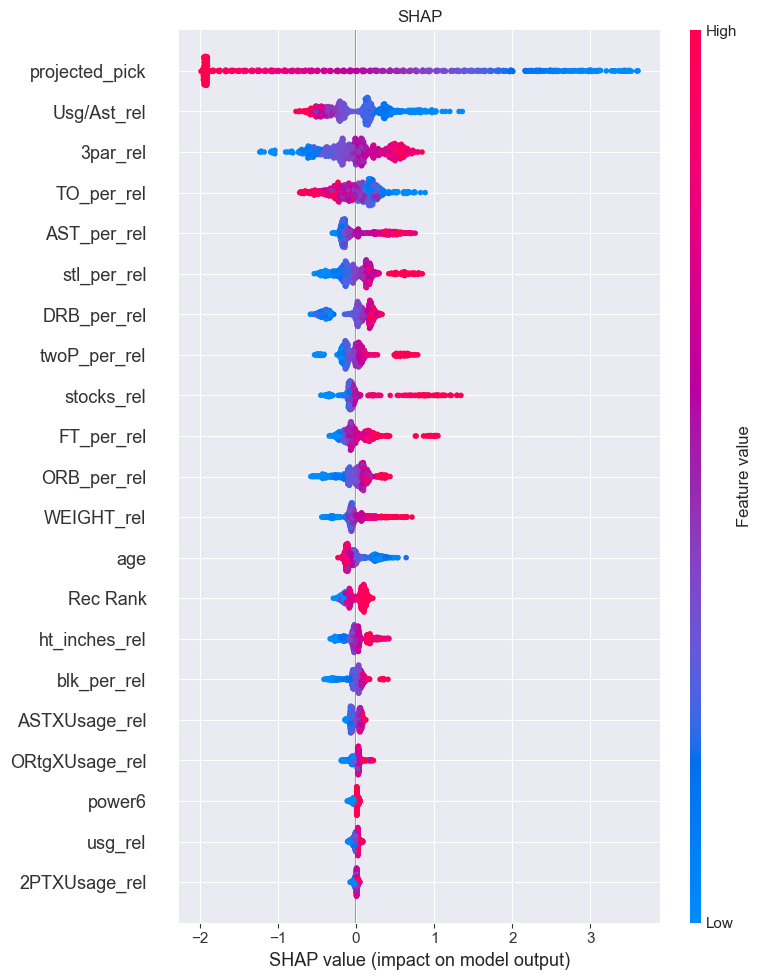

In [31]:
import shap, matplotlib.pyplot as plt
_Xg = apply_position_mask(d)[FEATURES].astype(np.float64).to_numpy()
sv = shap.TreeExplainer(model.model).shap_values(_Xg)
for k, gi in enumerate(model.lin_idx):                                    # add the linear mock-pick term
    gv = _Xg[:, gi].copy(); gv[np.isnan(gv)] = model.fill[k]
    sv[:, gi] = sv[:, gi] + model.lin.coef_[k] * (gv - model.fill[k])

imp = np.abs(sv).mean(axis=0); order = np.argsort(imp)[::-1]
print(f'=== mean |SHAP| (EPM), n={len(d)} ===')
for i in order:
    print(f'  {FEATURES[i]:<16} {imp[i]:.3f}')

shap.summary_plot(sv, _Xg, feature_names=FEATURES, show=False, max_display=len(FEATURES))
plt.title('SHAP'); plt.tight_layout(); plt.show()

## 9. Scores and boards

In [32]:
# Score every international with the final model; unmapped leagues get UNMAPPED_PENALTY off.
if _ir is not None:
    _X = apply_position_mask(_ir).reindex(columns=FEATURES).apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float64)
    _ir['pred_epm'] = model.predict(_X)
    _unm = _ir['translated_from'].astype(str).str.startswith('UNMAPPED')
    _ir.loc[_unm, 'pred_epm'] = _ir.loc[_unm, 'pred_epm'] - UNMAPPED_PENALTY
    print(f"UNMAPPED -{UNMAPPED_PENALTY:g} penalty applied to {int(_unm.sum())} internationals")

    _cov = apply_position_mask(_ir).reindex(columns=list(FEATURES)).notna().mean().sort_values()
    print("feature coverage for internationals (fraction non-NaN):"); print(_cov.round(2).to_string())
    _cols = [c for c in ['player_name', 'YEAR', 'projected_pick', 'realgm_league', 'translated_from', 'in_train', 'peak_epm', 'pred_epm'] if c in _ir.columns]
    intl_pred = _ir[_cols].sort_values('pred_epm', ascending=False)
    print("\nINTERNATIONAL PREDICTIONS" + ("" if SHOW_ALL else " (top 15)") + ":\n")
    print((intl_pred if SHOW_ALL else intl_pred.head(15)).to_string(index=False))
    intl_pred.to_csv('intl_predictions.csv', index=False)
else:
    print("_ir not built, run the internationals cell first")

UNMAPPED -3 penalty applied to 25 internationals
feature coverage for internationals (fraction non-NaN):
Rec Rank          0.00
Usg/Ast_rel       0.99
3par_rel          1.00
age               1.00
projected_pick    1.00
DRB_per_rel       1.00
ASTXUsage_rel     1.00
2PTXUsage_rel     1.00
WEIGHT_rel        1.00
ORB_per_rel       1.00
blk_per_rel       1.00
stl_per_rel       1.00
ht_inches_rel     1.00
stocks_rel        1.00
ORtgXUsage_rel    1.00
twoP_per_rel      1.00
TO_per_rel        1.00
FT_per_rel        1.00
AST_per_rel       1.00
power6            1.00
usg_rel           1.00

INTERNATIONAL PREDICTIONS (top 15):

       player_name  YEAR  projected_pick realgm_league          translated_from  in_train  peak_epm  pred_epm
    Alperen Sengün  2021               9         T-BSL              Turkish-BSL     False       NaN  6.514949
       Luka Doncic  2018               3           ACB              Spanish-ACB      True    9.1139  5.445991
 Victor Wembanyama  2023               1    

In [33]:
# Each class, college + international, ranked by predicted peak EPM (mock board only, pick <= 61)
_col = df_model[['player_name', 'draft_year', 'pred_epm', 'projected_pick']].copy()
_col['type'] = 'college'
_col = _col[pd.to_numeric(_col['projected_pick'], errors='coerce').le(61)]

_frames = [_col]
if _ir is not None:
    _i = intl_pred.rename(columns={'YEAR': 'draft_year'})[['player_name', 'draft_year', 'pred_epm', 'projected_pick']].copy()
    _i['type'] = 'INTL'
    _frames.append(_i)

_allp = pd.concat(_frames, ignore_index=True)
_allp['draft_year'] = pd.to_numeric(_allp['draft_year'], errors='coerce')

for y in sorted(_allp['draft_year'].dropna().unique()):
    if y < CURRENT_SEASON - (16 if SHOW_ALL else 2):
        continue
    yr = _allp[_allp['draft_year'] == y].sort_values('pred_epm', ascending=False).head(60 if SHOW_ALL else 15)
    print(f"\n===== {int(y)} DRAFT CLASS: predicted peak EPM =====")
    disp = yr[['player_name', 'type', 'projected_pick', 'pred_epm']].copy(); disp['pred_epm'] = disp['pred_epm'].round(2)
    print(disp.to_string(index=False))
    print(f"   ({int((yr['type'] == 'INTL').sum())} international in the top {len(yr)})")


===== 2024 DRAFT CLASS -- predicted peak EPM =====
       player_name    type  projected_pick  pred_epm
   Donovan Clingan college               5      5.72
     Reed Sheppard college               3      4.28
         Zach Edey college              13      3.21
   Kyle Filipowski college              28      2.34
      Nikola Topic    INTL              12      2.02
    Stephon Castle college               4      2.02
   DaRon Holmes II college              24      1.72
      Devin Carter college              10      1.62
    Rob Dillingham college              14      1.54
Carlton Carrington college              19      0.98
      Jared McCain college              16      0.92
       Kel'el Ware college              21      0.67
    Jonathan Mogbo college              41      0.64
       Ron Holland    INTL               5      0.49
    Ja'Kobe Walter college              17      0.44
   (2 international in the top 15)

===== 2025 DRAFT CLASS -- predicted peak EPM =====
         play

In [34]:
# One board across classes, college + international, ranked by predicted peak EPM
START_YEAR    = None        # e.g. 2026 for just the current class; None = every class
GATE_TO_BOARD = True        # False = include off-board players too
SHOW_N        = None if SHOW_ALL else 25

_frames = [pd.DataFrame({'name': df_model['player_name'], 'year': pd.to_numeric(df_model['draft_year'], errors='coerce'),
                         'college': df_model['team'],
                         'pred_epm': pd.to_numeric(df_model['pred_epm'], errors='coerce'),
                         '_pick': pd.to_numeric(df_model['projected_pick'], errors='coerce')})]
if _ir is not None:
    _frames.append(pd.DataFrame({'name': _ir['player_name'], 'year': pd.to_numeric(_ir['YEAR'], errors='coerce'),
                                 'college': _ir['realgm_league'],
                                 'pred_epm': pd.to_numeric(_ir['pred_epm'], errors='coerce'),
                                 '_pick': pd.to_numeric(_ir['projected_pick'], errors='coerce')}))

_all = pd.concat(_frames, ignore_index=True).dropna(subset=['pred_epm', 'year'])
if START_YEAR is not None: _all = _all[_all['year'] >= START_YEAR]
if GATE_TO_BOARD:          _all = _all[_all['_pick'] <= 61]
_all = _all.sort_values('pred_epm', ascending=False).drop(columns='_pick').reset_index(drop=True)
_all.index += 1
_all['year'] = _all['year'].astype(int)
_all['pred_epm'] = _all['pred_epm'].round(2)

print(f"=== {_all['year'].min()}-{_all['year'].max()}: {len(_all)} players across "
      f"{_all['year'].nunique()} classes ===")
print("players per class:")
print(_all['year'].value_counts().sort_index().to_string())
print(f"\n{_all.head(SHOW_N).to_string() if SHOW_N else _all.to_string()}")

=== 2010-2026 -- 1459 players across 17 classes ===
players per class:
year
2010     77
2011     77
2012     77
2013     70
2014     71
2015     70
2016     72
2017     73
2018     71
2019     97
2020    101
2021    105
2022    106
2023     92
2024     96
2025    106
2026     98

                  name  year         college  pred_epm
1       Alperen Sengün  2021           T-BSL      6.51
2          Joel Embiid  2014          Kansas      5.96
3       Cameron Boozer  2026            Duke      5.77
4   Karl-Anthony Towns  2015        Kentucky      5.74
5    Tyrese Haliburton  2020        Iowa St.      5.73
6      Donovan Clingan  2024     Connecticut      5.72
7        Anthony Davis  2012        Kentucky      5.68
8          Luka Doncic  2018             ACB      5.45
9        Kawhi Leonard  2011   San Diego St.      5.31
10        Caleb Wilson  2026  North Carolina      5.25
11       Chet Holmgren  2022         Gonzaga      5.22
12   Victor Wembanyama  2023      Jeep Elite      5.19
13  

## 10. Player tools
Explain a prediction, optionally with some stats changed.

In [35]:
import shap

NAME = 'Paolo Banchero'
YEAR = None           # draft class, if the name is shared
OVERRIDES = {}        # raw stat -> value, e.g. {'usg': 28.0, 'WEIGHT': 240}

def _lookup(name, year=None):
    """Matching players, best first: on the mock board, then the most recent class."""
    cands = []
    for tag, f in [('college', df_model), ('INTL', _ir)]:
        if f is None: continue
        h = f[f['player_name'].str.contains(name, case=False, na=False)]
        dy = pd.to_numeric(h['draft_year'], errors='coerce')
        if year is not None:
            h, dy = h[dy == year], dy[dy == year]
        on_board = pd.to_numeric(h['projected_pick'], errors='coerce') <= 61
        cands += [(bool(on_board[i]), dy[i] if pd.notna(dy[i]) else 0, tag, h.loc[[i]].copy()) for i in h.index]
    return sorted(cands, key=lambda c: (c[0], c[1]), reverse=True)

def _explain_row(frame):
    x = apply_position_mask(frame).reindex(columns=FEATURES).apply(pd.to_numeric, errors='coerce').to_numpy(dtype=np.float64)
    s = shap.TreeExplainer(model.model).shap_values(x)[0]
    for k, gi in enumerate(model.lin_idx):         # add the linear mock-pick term
        gv = model.fill[k] if np.isnan(x[0, gi]) else x[0, gi]
        s[gi] += model.lin.coef_[k] * (gv - model.fill[k])
    return model.predict(x)[0], x[0], s

def explain(name, overrides=None, year=None):
    cands = _lookup(name, year)
    if not cands:
        print(f"'{name}' not found in df_model or _ir."); return
    _, _, tag, fr = cands[0]
    row = fr.iloc[0]
    pen = UNMAPPED_PENALTY if str(row.get('translated_from', '')).startswith('UNMAPPED') else 0.0
    p0, x0, s0 = _explain_row(fr)
    yr = row.get('draft_year', row.get('YEAR'))
    print(f"{row['player_name']}  ({tag}, {int(yr) if pd.notna(yr) else '?'})")
    if tag == 'INTL':
        print(f"league: {row.get('realgm_league')}  ->  {row.get('translated_from')}")
    print(f"predicted peak EPM: {p0 - pen:+.2f}" + (f"   (incl. -{pen:g} unmapped-league penalty)" if pen else ''))
    print(f"missing features: {[f for f, v in zip(FEATURES, x0) if np.isnan(v)] or 'none'}")
    if len(cands) > 1:
        print("other matches (pass year= to pick one): " + ', '.join(
            f"{c[3]['player_name'].iloc[0]} {int(c[1])}" + ('' if c[0] else ' (off-board)') for c in cands[1:6]))
    print()

    ov = overrides or {}
    if ov:
        fr2 = fr.copy()
        for k, v in ov.items():
            fr2[k] = v
        add_derived(fr2)                           # so interactions follow the new raw stats
        p1, x1, s1 = _explain_row(fr2)
        print(f"with {ov}: {p1 - pen:+.2f}   ({p1 - p0:+.2f})\n")
    else:
        x1, s1 = x0, s0

    print(f"{'feature':<16}{'value':>9}{'SHAP':>8}" + (f"{'new val':>10}{'new SHAP':>10}" if ov else ''))
    for i in np.argsort(-np.abs(s1)):
        print(f"{FEATURES[i]:<16}{x0[i]:>9.2f}{s0[i]:>+8.3f}" + (f"{x1[i]:>10.2f}{s1[i]:>+10.3f}" if ov else ''))

explain(NAME, OVERRIDES, YEAR)

Paolo Banchero  (college, 2022)
predicted peak EPM: +3.36
missing features: none

feature             value    SHAP
projected_pick       1.00  +3.452
3par_rel            -0.07  -0.444
Usg/Ast_rel         -0.46  +0.440
AST_per_rel          5.70  +0.360
age                 19.22  +0.311
ht_inches_rel        2.00  +0.276
DRB_per_rel          1.50  +0.184
WEIGHT_rel          16.70  +0.178
Rec Rank            99.80  +0.144
FT_per_rel          -0.03  -0.083
ASTXUsage_rel      195.20  +0.067
stocks_rel          -0.20  -0.060
ORtgXUsage_rel     276.56  +0.040
stl_per_rel          0.00  -0.036
TO_per_rel          -0.10  +0.035
blk_per_rel          0.10  +0.033
usg_rel              2.60  +0.028
twoP_per_rel         0.01  +0.013
power6               1.00  +0.013
2PTXUsage_rel        1.58  +0.010
ORB_per_rel         -0.50  -0.001


## 11. App export
Writes the board and model to `epm-projections/artifacts/`. Re-run after a refit.

In [36]:
import json

TRAIN_YEARS = set(pd.to_numeric(d['draft_year'], errors='coerce').dropna().astype(int))

_c = df_model.copy()
_frames = [pd.DataFrame({'player': _c['player_name'], 'year': pd.to_numeric(_c['draft_year'], errors='coerce'),
                         'school': _c['team'], 'type': 'college',
                         'mock_pick': pd.to_numeric(_c['projected_pick'], errors='coerce'),
                         'pred_epm': pd.to_numeric(_c['pred_epm'], errors='coerce')})]
if _ir is not None:
    _frames.append(pd.DataFrame({'player': _ir['player_name'], 'year': pd.to_numeric(_ir['YEAR'], errors='coerce'),
                                 'school': _ir['realgm_league'], 'type': 'INTL',
                                 'mock_pick': pd.to_numeric(_ir['projected_pick'], errors='coerce'),
                                 'pred_epm': pd.to_numeric(_ir['pred_epm'], errors='coerce')}))
_board = pd.concat(_frames, ignore_index=True).dropna(subset=['pred_epm', 'year'])
_board['year'] = _board['year'].astype(int)
_board = _board[(~_board['year'].isin(TRAIN_YEARS)) & (_board['mock_pick'] <= 61)].drop_duplicates(['player', 'year'])

_board['model_rank'] = _board.groupby('year')['pred_epm'].rank(ascending=False, method='first').astype(int)
_board['mock_rank']  = _board.groupby('year')['mock_pick'].rank(method='first').astype(int)
_board = _board.sort_values(['year', 'model_rank'])

_ty = sorted(TRAIN_YEARS)
print(f"training classes: {_ty}")
print(f"non-training classes: {sorted(int(y) for y in _board['year'].unique())}  ({len(_board)} players)")

# app export (commit + push epm-projections to publish)
SITE_ART = 'epm-projections/artifacts'
if os.path.isdir(SITE_ART):
    _board[['player', 'year', 'school', 'type', 'mock_pick', 'model_rank', 'mock_rank', 'pred_epm']].assign(
        pred_epm=lambda q: q['pred_epm'].round(2)).to_csv(f'{SITE_ART}/draft_rankings.csv', index=False)
    with open(f'{SITE_ART}/draft_meta.json', 'w') as fh:
        json.dump({'train_years': _ty}, fh)

    # model for the app's "Build a prospect" form. draft_model.py rebuilds the features from raw
    # stats; re-scoring the board through it below catches any drift from this notebook.
    import sys, importlib
    if 'epm-projections' not in sys.path: sys.path.insert(0, 'epm-projections')
    import draft_model as _dm; importlib.reload(_dm)
    _RAW = _dm.raw_inputs(FEATURES, SIZE_REL)
    model.model.save_model(f'{SITE_ART}/draft_xgb.json')
    _inp_ref = d.reindex(columns=_RAW).apply(pd.to_numeric, errors='coerce')
    _bundle = {
        'features': list(FEATURES),
        'size_rel': dict(SIZE_REL),
        'size_med': {k: {str(g): float(v) for g, v in s.items()} for k, s in _SIZE_MED.items()},
        'position_mask': {k: ([v] if isinstance(v, str) else list(v)) for k, v in POSITION_MASK.items()},
        'feature_caps': {k: float(v) for k, v in FEATURE_CAPS.items()},
        'lin': None if model.lin is None else {
            'idx': [int(i) for i in model.lin_idx], 'coef': [float(c) for c in model.lin.coef_],
            'intercept': float(model.lin.intercept_), 'fill': [float(v) for v in model.fill]},
        'inputs': {c: {'median': float(_inp_ref[c].median()), 'lo': float(_inp_ref[c].quantile(0.01)),
                       'hi': float(_inp_ref[c].quantile(0.99))} for c in _RAW},
    }
    with open(f'{SITE_ART}/draft_model.json', 'w') as fh:
        json.dump(_bundle, fh, indent=1)

    # raw inputs for every board player, so the form can start from a real prospect
    _src = [_c.assign(year=pd.to_numeric(_c['draft_year'], errors='coerce'), type='college', penalty=0.0)]
    if _ir is not None:
        _unm = _ir['translated_from'].astype(str).str.startswith('UNMAPPED')
        _src.append(_ir.assign(year=pd.to_numeric(_ir['YEAR'], errors='coerce'), type='INTL',
                               penalty=np.where(_unm, UNMAPPED_PENALTY, 0.0)))
    _inp = pd.concat([s.reindex(columns=['player_name', 'year', 'type', 'penalty', 'pred_epm', *_RAW])
                       .assign(grp=_pos_group(s).values) for s in _src], ignore_index=True)
    # filter in the same order as _board so same-named players resolve to the same person
    _inp = (_inp.rename(columns={'player_name': 'player'})
                .assign(pred_epm=lambda q: pd.to_numeric(q['pred_epm'], errors='coerce'),
                        year=lambda q: pd.to_numeric(q['year'], errors='coerce'))
                .dropna(subset=['pred_epm', 'year'])
                .assign(year=lambda q: q['year'].astype(int)))
    _inp = (_inp[(~_inp['year'].isin(TRAIN_YEARS)) & (pd.to_numeric(_inp['projected_pick'], errors='coerce') <= 61)]
                .drop_duplicates(['player', 'year'])
                .merge(_board[['player', 'year', 'pred_epm']].rename(columns={'pred_epm': 'board_epm'}),
                       on=['player', 'year']))
    _bst = _dm.load(SITE_ART)[1]
    _diff = np.abs(_dm.predict(_inp, _bundle, _bst) - _inp['penalty'] - _inp['board_epm'])
    print(f"draft_model.py reproduces the board: max |diff| = {np.nanmax(_diff):.4f} over {len(_inp)} players"
          + ("" if np.nanmax(_diff) < 1e-3 else "   <-- MISMATCH: update DERIVED in draft_model.py"))
    _inp.drop(columns=['pred_epm', 'board_epm']).to_csv(f'{SITE_ART}/draft_inputs.csv', index=False)
    print(f"wrote {SITE_ART}/draft_rankings.csv, draft_meta.json, draft_model.json, draft_xgb.json, draft_inputs.csv")

training classes: [2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020]
non-training classes: [2021, 2022, 2023, 2024, 2025, 2026]  (603 players)
wrote /Users/dannyharlan/Personal_Projects/darko_rankings.html
draft_model.py reproduces the board: max |diff| = 0.0000 over 603 players
wrote epm-projections/artifacts/draft_rankings.csv, draft_meta.json, draft_model.json, draft_xgb.json, draft_inputs.csv


True